# Exercise 4: RF to analytic and baseband IQ

## Question

How do two ways of making complex RF data compare in accuracy, memory, and time on CPU and GPU—when does parallel CPU conversion help, and how does PICMUS conversion scale with transmit-angle count?

We use two measured datasets with very different trace lengths, keep file loading outside the conversion timers, and pass both conversion outputs through Mach with the matching modulation-frequency setting. The notebook is prepared for a VS Code kernel connected to a Colab T4.


## Methods and interpretation

| Representation | CPU | GPU | Mach modulation frequency |
|---|---|---|---|
| Analytic RF | `scipy.signal.hilbert` | `cupyx.scipy.signal.hilbert` | `0 Hz` |
| Baseband IQ | PyMUST-style complex downmix + 5th-order Butterworth low-pass | CuPy/CuPyX equivalent | Dataset carrier: PyMUST metadata; PICMUS specification |

Hilbert creates an analytic signal while retaining its RF carrier; the Hilbert conversion itself does not need the carrier frequency. Downmixing needs the carrier to shift the signal to zero frequency before filtering away the unwanted sideband. For PICMUS, the carrier is also used to demodulate Hilbert output for a valid complex-sample comparison. PyMUST’s carrier lies above Nyquist, so that comparison is disabled there. Mach uses modulation frequency only for complex IQ phase correction: use 0 Hz for carrier-bearing analytic RF and the dataset carrier for baseband IQ. Compare B-mode magnitudes after beamforming with the matching setting for each representation.

The PyMUST rotating-disk RF is bandpass-sampled: its 5.000 MHz carrier is above the 3.333 MHz Nyquist frequency at 6.667 MHz sampling. Standard discrete Hilbert selects positive *sampled* frequencies, which are the wrong sideband for the physical positive-frequency RF here. Keep that standard Hilbert timing and CPU/GPU parity result, but treat its PyMUST image as diagnostic. The alias-aware diagnostic below asks whether we can select the correct physical sideband and reproduce PyMUST's baseband IQ. PICMUS is sampled above twice its 5.208 MHz carrier, so its existing cross-method check remains interpretable.

The PyMUST acquisition metadata gives a 15% fractional bandwidth. With a 5 MHz carrier, that is a nominal 750 kHz full bandwidth, or 4.625–5.375 MHz. At 6.667 MHz sampling, this band folds to about −2.042 to −1.292 MHz; the positive physical RF lobe therefore appears on the negative sampled-frequency side. The new diagnostic measures the RF spectrum to check this estimate, retains and doubles that lobe, then applies PyMUST's mixer `exp(−j2πfc(n/fs+t0))` and low-pass filter. Selecting and doubling the physical positive-frequency lobe establishes the analytic-signal scale, so the diagnostic does not multiply by two again after mixing. The same `t0` and mixer sign fix the IQ phase convention. This FFT spectrum-selection path is diagnostic and is kept separate from the CPU/GPU timing comparison. See the [MUST acquisition example](https://www.biomecardio.com/MUST/functions/MUST%20user%20guide.pdf) and [PyMUST `rf2iq`](https://github.com/creatis-ULTIM/PyMUST/blob/fe73cc3911a51b48b36095c2e0ad29c266532447/src/pymust/rf2iq.py).

The PyMUST rotating-disk recording is a short slow-time ensemble. PICMUS contains a much longer fast-time record for each of 75 independent transmit angles and one imaging frame. Its UFF `pulse` object is absent, so the carrier is not available as `channel_data.pulse.center_frequency`. The [PICMUS transmit-pulse specification](https://www.creatis.insa-lyon.fr/Challenge/IEEE_IUS_2016/transmit_pulse) sets the transmit frequency to 5.208 MHz (the nearest Verasonics Vantage setting to the roughly 5.13 MHz target). The UFF modulation-frequency field is 0 Hz for raw RF; Mach’s [UFF adapter](https://github.com/Forest-Neurotech/mach/blob/v0.2.1/src/mach/io/uff.py#L63-L94) uses that value to select its analytic-signal Hilbert path. The notebook bypasses that adapter preprocessing for the timed paths and records geometry setup separately from raw file loading.


## 1. Configure the run

Open this notebook in VS Code, connect its kernel to the Colab T4, and run the install cell. If pip asks for a kernel restart, restart it before continuing. The notebook uses a vectorized CPU baseline and a small CPU worker sweep over complete receive traces; the fast-time samples of a trace stay together.

The timing report separates cache/download and UFF loading, input upload, conversion compute, output download, and transfer-inclusive conversion-to-image time. CPU worker counts, data sizes, and sampled peak memory deltas are reported alongside CPU/GPU numerical differences. Memory deltas are sampled estimates; exact raw and output payload sizes are recorded separately. A deterministic fourfold synthetic workload follows the real-data angle sweep. It is streamed through PICMUS-sized GPU batches so its total scale can be measured without one oversized GPU allocation.


In [18]:
from pathlib import Path
import os

RUN_CPU_WORKER_SWEEP = True
RUN_BEAMFORM_IMAGE_CHECKS = True
RUN_SYNTHETIC_SCALE_CASE = True  # Four times the measured PICMUS trace count.
RUN_PICMUS_ANGLE_SCALING = True
CPU_WORKERS = (1, 2, 4)
WARMUP_RUNS = 1
MEASURED_RUNS = 3
SYNTHETIC_SCALE_MULTIPLIER = 4

_candidates = [Path("/content/realtime-beamforming-lab"), Path.cwd(), *Path.cwd().resolve().parents]
ROOT = next((p.resolve() for p in _candidates if (p / "pyproject.toml").is_file()), Path.cwd().resolve())
RESULTS_DIR = ROOT / "results"
ARTIFACTS_DIR = ROOT / "artifacts"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("Kernel working directory:", ROOT)
print("Results:", RESULTS_DIR)
print("Artifacts:", ARTIFACTS_DIR)
print("CPU workers:", CPU_WORKERS)


Kernel working directory: /content/realtime-beamforming-lab
Results: /content/realtime-beamforming-lab/results
Artifacts: /content/realtime-beamforming-lab/artifacts
CPU workers: (1, 2, 4)


### Install the Colab dependencies

This installs the Colab CUDA extra used by the lab and removes conflicting CuPy CUDA wheels first. Run it on the connected T4, then restart the kernel if requested.


In [19]:
%pip uninstall -y cupy-cuda12x cupy-cuda13x
%pip install --no-cache-dir "mach-beamform[examples,uff,vis]>=0.2.1,<0.3.0" "cupy-cuda13x>=13.0" "pymust>=0.1.9" "psutil>=5.9"


Found existing installation: cupy-cuda13x 14.2.0
Uninstalling cupy-cuda13x-14.2.0:
  Successfully uninstalled cupy-cuda13x-14.2.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 174.2 MB/s  0:00:00 eta 0:00:01


In [20]:
import importlib.metadata as metadata
import platform
import subprocess
import sys

import cupy as cp
import numpy as np
import scipy

_gpu = subprocess.run(["nvidia-smi"], text=True, capture_output=True)
print(_gpu.stdout if _gpu.returncode == 0 else _gpu.stderr)
if _gpu.returncode != 0 or cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("No CUDA device is visible. Connect the notebook to a Colab T4 GPU runtime.")

_device = cp.cuda.runtime.getDeviceProperties(0)
_gpu_name = _device["name"].decode() if isinstance(_device["name"], bytes) else str(_device["name"])
print("Python:", platform.python_version())
print("GPU:", _gpu_name)
for _package in ("mach-beamform", "cupy-cuda13x", "PyMUST", "scipy", "pyuff-ustb"):
    try:
        print(f"{_package}: {metadata.version(_package)}")
    except metadata.PackageNotFoundError:
        print(f"{_package}: version metadata unavailable")


Sun Nov  8 23:55:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   69C    P0             31W /   70W |   14707MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Load raw RF and acquisition metadata

The dataset loader and array layout conversion happen once. PICMUS has no UFF pulse object; its 5.208 MHz transmit frequency comes from the [PICMUS challenge specification](https://www.creatis.insa-lyon.fr/Challenge/IEEE_IUS_2016/transmit_pulse). Its zero modulation-frequency field is retained as the Mach setting for analytic RF and is not treated as the carrier.


In [21]:
import hashlib
import time

from mach.io.must import download_pymust_doppler_data, extract_pymust_params
from mach.io.utils import cached_download
from pyuff_ustb import Uff


def scalar(value, name):
    array = np.asarray(value).squeeze()
    if array.size != 1:
        raise ValueError(f"Expected scalar metadata for {name}; got shape {array.shape}")
    return float(array)


def array_fingerprint(array):
    contiguous = np.ascontiguousarray(array)
    digest = hashlib.sha256()
    digest.update(contiguous.dtype.str.encode("ascii"))
    digest.update(np.asarray(contiguous.shape, dtype="<i8").tobytes())
    digest.update(contiguous.tobytes(order="C"))
    return digest.hexdigest()

# PyMUST PWI_disk.mat: loader verifies the upstream file hash.
_load_start = time.perf_counter_ns()
pymust_mat = download_pymust_doppler_data()
pymust_params = extract_pymust_params(pymust_mat)
pymust_rf_original = np.asarray(pymust_mat["RF"])
pymust_load_ms = (time.perf_counter_ns() - _load_start) / 1e6

pymust_rf = np.ascontiguousarray(pymust_rf_original, dtype=np.float32)
pymust_meta = {
    "fs_hz": scalar(pymust_params["fs"], "PyMUST fs"),
    "fc_hz": scalar(pymust_params["fc"], "PyMUST fc"),
    "t0_s": scalar(pymust_params.get("t0", 0.0), "PyMUST t0"),
    "bandwidth_percent": (
        scalar(pymust_params["bandwidth"], "PyMUST bandwidth")
        if pymust_params.get("bandwidth", None) is not None else None
    ),
    "_pymust_params": pymust_params,
}

# PICMUS experimental resolution/distortion UFF.
PICMUS_URL = "https://zenodo.org/records/20261898/files/PICMUS_experiment_resolution_distortion.uff"
PICMUS_FILENAME = "PICMUS_experiment_resolution_distortion.uff"
PICMUS_SIZE = 145_518_524
PICMUS_SHA256 = "c93af0781daeebf771e53a42a629d4f311407410166ef2f1d227e9d2a1b8c641"
PICMUS_TRANSMIT_FREQUENCY_HZ = 5.208e6  # PICMUS challenge transmit-pulse specification.
_download_start = time.perf_counter_ns()
picmus_path = cached_download(
    PICMUS_URL, expected_size=PICMUS_SIZE, expected_hash=PICMUS_SHA256,
    digest=hashlib.sha256, filename=PICMUS_FILENAME,
)
picmus_download_cache_ms = (time.perf_counter_ns() - _download_start) / 1e6
_parse_start = time.perf_counter_ns()
uff = Uff(str(picmus_path))
picmus_channel_data = uff.read("/channel_data")
picmus_scan = uff.read("/scan")
picmus_rf_original = np.asarray(picmus_channel_data.data)
if picmus_rf_original.ndim == 3:
    picmus_rf_original = picmus_rf_original[..., None]
picmus_rf = np.ascontiguousarray(picmus_rf_original, dtype=np.float32)
picmus_parse_array_ms = (time.perf_counter_ns() - _parse_start) / 1e6

picmus_carrier_hz = PICMUS_TRANSMIT_FREQUENCY_HZ
picmus_modulation_hz = float(picmus_channel_data.modulation_frequency)
picmus_pulse_metadata_present = picmus_channel_data.pulse is not None
if not np.isfinite(picmus_carrier_hz) or picmus_carrier_hz <= 0:
    raise ValueError("PICMUS transmit frequency is missing or invalid; verify the challenge specification.")
if picmus_modulation_hz != 0.0:
    raise ValueError(
        f"Expected real raw PICMUS RF with modulation_frequency=0 Hz; got {picmus_modulation_hz}. "
        "Inspect the dataset representation before continuing."
    )

picmus_meta = {
    "fs_hz": float(picmus_channel_data.sampling_frequency),
    "fc_hz": picmus_carrier_hz,
    "t0_s": float(picmus_channel_data.initial_time),
    "bandwidth_percent": None,  # Use PyMUST's default low-pass cutoff rule for this comparison.
}

datasets = {
    "pymust": {
        "label": "PyMUST rotating-disk phantom",
        "raw": pymust_rf,
        "rf_matrix": np.ascontiguousarray(pymust_rf.reshape(pymust_rf.shape[0], -1)),
        "meta": pymust_meta,
        "original": pymust_rf_original,
        "pymust_params": pymust_params,
        "load_ms": float(pymust_load_ms),
        "file_sha256": "c349dc1d677c561434fd0e4a74142c4a0a44b7e6ae0a42d446c078a528ef58c1",
        "rf_array_sha256": array_fingerprint(pymust_rf),
    },
    "picmus": {
        "label": "PICMUS experimental resolution/distortion phantom",
        "raw": picmus_rf,
        "rf_matrix": np.ascontiguousarray(picmus_rf.reshape(picmus_rf.shape[0], -1)),
        "meta": picmus_meta,
        "original": picmus_rf_original,
        "channel_data": picmus_channel_data,
        "scan": picmus_scan,
        "load_ms": float(picmus_download_cache_ms + picmus_parse_array_ms),
        "download_cache_ms": float(picmus_download_cache_ms),
        "uff_parse_array_ms": float(picmus_parse_array_ms),
        "file_sha256": PICMUS_SHA256,
        "rf_array_sha256": array_fingerprint(picmus_rf),
        "uff_modulation_frequency_hz": picmus_modulation_hz,
        "uff_pulse_metadata_present": picmus_pulse_metadata_present,
    },
}

for _name, _item in datasets.items():
    _rf = _item["raw"]
    print(
        f"{_name}: raw shape={_rf.shape}, traces={_item['rf_matrix'].shape[1]:,}, "
        f"dtype={_rf.dtype}, bytes={_rf.nbytes / 1e6:.1f} MB, "
        f"fs={_item['meta']['fs_hz']/1e6:.3f} MHz, fc={_item['meta']['fc_hz']/1e6:.3f} MHz, "
        f"load/cache={_item['load_ms']:.1f} ms"
    )
print("PICMUS transmit frequency (challenge specification):", picmus_carrier_hz / 1e6, "MHz")
print("PICMUS UFF pulse metadata present:", picmus_pulse_metadata_present)
print("PICMUS modulation-frequency metadata:", picmus_modulation_hz, "Hz")


pymust: raw shape=(334, 128, 32), traces=4,096, dtype=float32, bytes=5.5 MB, fs=6.667 MHz, fc=5.000 MHz, load/cache=32.0 ms
picmus: raw shape=(3328, 128, 75, 1), traces=9,600, dtype=float32, bytes=127.8 MB, fs=20.832 MHz, fc=5.208 MHz, load/cache=616.5 ms
PICMUS transmit frequency (challenge specification): 5.208 MHz
PICMUS UFF pulse metadata present: False
PICMUS modulation-frequency metadata: 0.0 Hz


## 3. Implement matched conversion paths

For the PyMUST dataset, the vectorized single-worker CPU baseline calls `pymust.rf2iq`; its worker sweep applies the same operations to independent trace chunks. PICMUS uses the matching SciPy implementation. The baseband path follows [PyMUST's `rf2iq` implementation](https://github.com/creatis-ULTIM/PyMUST/blob/fe73cc3911a51b48b36095c2e0ad29c266532447/src/pymust/rf2iq.py): complex mixing at the carrier, a fifth-order Butterworth low-pass, zero-phase forward/backward filtering, and a factor of two for envelope amplitude. The GPU Hilbert implementation is [CuPy's signal API](https://docs.cupy.dev/en/stable/reference/generated/cupyx.scipy.signal.hilbert.html). Its cutoff follows PyMUST's optional-bandwidth rule when PyMUST metadata supplies a bandwidth; otherwise it uses the default `min(2 fc / fs, 0.5)` normalized cutoff. Both outputs are stored as complex64 for the CPU/GPU comparison.

PICMUS has 128 receive channels × 75 transmit angles = 9,600 independent fast-time traces. The loader flattens the channel and angle axes into trace columns; CPU workers split those columns, while the GPU receives the full matrix. Each trace stays intact along fast time. This is one channel-angle trace workload, not a channel-only pass followed by a second angle-parallel pass.

### PyMUST alias-aware diagnostic

The timing comparison above keeps the ordinary Hilbert implementation unchanged. For PyMUST only, an added diagnostic estimates the windowed average RF spectrum across traces, checks how much power lies in the nominal aliased band and its mirror, and reports the measured peak and contiguous −6 dB span. It then builds an analytic signal by retaining and doubling only the negative-frequency alias band that corresponds to positive physical RF. The signal is downmixed with PyMUST's carrier, `t0`, and sign convention, then passed through the same low-pass filter. We compare complex samples directly with `pymust.rf2iq`, validate the phase sign using a synthetic signal with known phase, and compare Mach beamformed images. This is an accuracy/reconstruction check, not a third timed benchmark path.


In [22]:
from concurrent.futures import ThreadPoolExecutor
import gc
import threading

from scipy import signal as scipy_signal


def filter_cutoff(meta):
    fs_hz, fc_hz = meta["fs_hz"], meta["fc_hz"]
    bandwidth = meta.get("bandwidth_percent")
    if bandwidth is None:
        wn = min(2.0 * fc_hz / fs_hz, 0.5)
    else:
        wn = (fc_hz * bandwidth / 100.0) / fs_hz
    if not (0.0 < wn <= 1.0):
        raise ValueError(f"Invalid normalized Butterworth cutoff {wn}")
    return float(wn)


def cpu_convert(method, rf_matrix, meta):
    if method == "hilbert":
        result = scipy_signal.hilbert(rf_matrix, axis=0)
    elif method == "baseband":
        fs_hz, fc_hz, t0_s = meta["fs_hz"], meta["fc_hz"], meta["t0_s"]
        t0 = np.asarray(t0_s, dtype=np.float64)
        if t0.size == 1:
            t = np.arange(rf_matrix.shape[0], dtype=np.float64) / fs_hz + float(t0.reshape(-1)[0])
        elif t0.size == rf_matrix.shape[0]:
            t = np.arange(rf_matrix.shape[0], dtype=np.float64) / fs_hz + t0.reshape(-1)
        else:
            raise ValueError("t0 must be scalar or one value per fast-time sample")
        mixer = np.exp(-2j * np.pi * fc_hz * t).reshape(-1, 1)
        mixed = rf_matrix * mixer
        b, a = scipy_signal.butter(5, filter_cutoff(meta))
        result = scipy_signal.filtfilt(b, a, mixed, axis=0) * 2.0
    else:
        raise ValueError(method)
    return np.ascontiguousarray(result, dtype=np.complex64)


def cpu_convert_workers(method, rf_matrix, meta, workers):
    workers = min(int(workers), rf_matrix.shape[1])
    if workers <= 1:
        if method == "baseband" and "_pymust_params" in meta:
            import pymust
            result = pymust.rf2iq(rf_matrix, meta["_pymust_params"])
            return np.ascontiguousarray(result, dtype=np.complex64)
        return cpu_convert(method, rf_matrix, meta)
    bounds = np.linspace(0, rf_matrix.shape[1], workers + 1, dtype=int)
    chunks = [(int(bounds[i]), int(bounds[i + 1])) for i in range(workers)]
    with ThreadPoolExecutor(max_workers=workers) as pool:
        parts = list(pool.map(lambda pair: cpu_convert(method, rf_matrix[:, pair[0]:pair[1]], meta), chunks))
    return np.ascontiguousarray(np.concatenate(parts, axis=1), dtype=np.complex64)


def gpu_convert(method, rf_device, meta):
    from cupyx.scipy import signal as cupy_signal
    if method == "hilbert":
        result = cupy_signal.hilbert(rf_device, axis=0)
    elif method == "baseband":
        fs_hz, fc_hz, t0_s = meta["fs_hz"], meta["fc_hz"], meta["t0_s"]
        t0 = np.asarray(t0_s, dtype=np.float64)
        if t0.size == 1:
            t = cp.arange(rf_device.shape[0], dtype=cp.float64) / fs_hz + float(t0.reshape(-1)[0])
        elif t0.size == rf_device.shape[0]:
            t = cp.arange(rf_device.shape[0], dtype=cp.float64) / fs_hz + cp.asarray(t0.reshape(-1))
        else:
            raise ValueError("t0 must be scalar or one value per fast-time sample")
        mixer = cp.exp(-2j * cp.pi * fc_hz * t).astype(cp.complex64).reshape(-1, 1)
        mixed = rf_device * mixer
        b, a = cupy_signal.butter(5, filter_cutoff(meta))
        result = cupy_signal.filtfilt(b, a, mixed, axis=0) * 2.0
    else:
        raise ValueError(method)
    return cp.ascontiguousarray(result, dtype=cp.complex64)


def percentile_summary(samples):
    values = np.asarray(samples, dtype=np.float64)
    return {"samples_ms": values.tolist(), "p50_ms": float(np.percentile(values, 50)), "p95_ms": float(np.percentile(values, 95))}


def time_cpu(method, rf_matrix, meta, workers):
    for _ in range(WARMUP_RUNS):
        cpu_convert_workers(method, rf_matrix, meta, workers)
    samples, latest = [], None
    for _ in range(MEASURED_RUNS):
        started = time.perf_counter_ns()
        latest = cpu_convert_workers(method, rf_matrix, meta, workers)
        samples.append((time.perf_counter_ns() - started) / 1e6)
    return percentile_summary(samples), latest


def time_gpu(method, rf_device, meta):
    # Capture first-call planning/JIT overhead separately from steady-state samples.
    started = time.perf_counter_ns()
    cold = gpu_convert(method, rf_device, meta)
    cp.cuda.Device().synchronize()
    cold_wall_ms = (time.perf_counter_ns() - started) / 1e6
    del cold
    for _ in range(WARMUP_RUNS):
        gpu_convert(method, rf_device, meta)
    cp.cuda.Device().synchronize()
    wall, device, latest = [], [], None
    for _ in range(MEASURED_RUNS):
        start_event, end_event = cp.cuda.Event(), cp.cuda.Event()
        started = time.perf_counter_ns()
        start_event.record()
        latest = gpu_convert(method, rf_device, meta)
        end_event.record()
        cp.cuda.Device().synchronize()
        wall.append((time.perf_counter_ns() - started) / 1e6)
        device.append(float(cp.cuda.get_elapsed_time(start_event, end_event)))
    return {"cold_first_call_wall_ms": float(cold_wall_ms), "wall": percentile_summary(wall), "device_event": percentile_summary(device)}, latest


def current_rss_mib():
    with open("/proc/self/statm", "r", encoding="ascii") as handle:
        resident_pages = int(handle.read().split()[1])
    return resident_pages * os.sysconf("SC_PAGE_SIZE") / (1024 ** 2)


def sampled_peak_memory(fn, device=False, interval_s=0.002):
    gc.collect()
    base_host = current_rss_mib()
    base_device = cp.get_default_memory_pool().used_bytes() if device else 0
    stop = threading.Event()
    peak_host, peak_device = [base_host], [base_device]
    def sample():
        while not stop.wait(interval_s):
            peak_host[0] = max(peak_host[0], current_rss_mib())
            if device:
                peak_device[0] = max(peak_device[0], cp.get_default_memory_pool().used_bytes())
    thread = threading.Thread(target=sample, daemon=True)
    thread.start()
    result = fn()
    if device:
        cp.cuda.Device().synchronize()
        peak_device[0] = max(peak_device[0], cp.get_default_memory_pool().used_bytes())
    peak_host[0] = max(peak_host[0], current_rss_mib())
    stop.set()
    thread.join()
    memory = {"sampled_host_rss_delta_mib": float(max(0.0, peak_host[0] - base_host))}
    if device:
        memory["sampled_cupy_pool_peak_delta_mib"] = float(max(0, peak_device[0] - base_device) / (1024 ** 2))
    return memory, result


def normalized_l2(reference, candidate):
    reference = np.asarray(reference)
    candidate = np.asarray(candidate)
    denominator = float(np.linalg.norm(reference.ravel().astype(np.complex128)))
    numerator = float(np.linalg.norm((reference - candidate).ravel().astype(np.complex128)))
    return numerator / denominator if denominator else 0.0

def pymust_alias_band(meta):
    fs_hz, fc_hz = float(meta["fs_hz"]), float(meta["fc_hz"])
    bandwidth_percent = meta.get("bandwidth_percent")
    if bandwidth_percent is None:
        raise ValueError("Alias-aware conversion requires the PyMUST bandwidth metadata.")
    bandwidth_hz = fc_hz * float(bandwidth_percent) / 100.0
    alias_center_hz = (fc_hz + fs_hz / 2.0) % fs_hz - fs_hz / 2.0
    alias_order = int(round((fc_hz - alias_center_hz) / fs_hz))
    physical_low_hz = fc_hz - bandwidth_hz / 2.0
    physical_high_hz = fc_hz + bandwidth_hz / 2.0
    alias_low_hz = physical_low_hz - alias_order * fs_hz
    alias_high_hz = physical_high_hz - alias_order * fs_hz
    if not (-fs_hz / 2.0 < alias_low_hz < alias_high_hz < 0.0):
        raise ValueError(
            "This diagnostic expects the positive physical RF band to map wholly "
            "inside the negative half of the sampled Nyquist interval."
        )
    return {
        "sampling_frequency_hz": fs_hz,
        "carrier_frequency_hz": fc_hz,
        "bandwidth_percent": float(bandwidth_percent),
        "bandwidth_hz": bandwidth_hz,
        "physical_band_hz": [physical_low_hz, physical_high_hz],
        "alias_order": alias_order,
        "alias_center_hz": alias_center_hz,
        "selected_alias_band_hz": [alias_low_hz, alias_high_hz],
        "mirror_alias_band_hz": [-alias_high_hz, -alias_low_hz],
        "nyquist_hz": fs_hz / 2.0,
    }


def pymust_alias_spectrum(rf_matrix, meta):
    band = pymust_alias_band(meta)
    n_samples = rf_matrix.shape[0]
    window = np.hanning(n_samples).astype(np.float64).reshape(-1, 1)
    spectrum = np.fft.fftshift(np.fft.fft(np.asarray(rf_matrix, dtype=np.float64) * window, axis=0), axes=0)
    power = np.mean(np.abs(spectrum) ** 2, axis=1)
    frequency_hz = np.fft.fftshift(np.fft.fftfreq(n_samples, d=1.0 / band["sampling_frequency_hz"]))
    low_hz, high_hz = band["selected_alias_band_hz"]
    selected = (frequency_hz >= low_hz) & (frequency_hz <= high_hz)
    mirror = (frequency_hz >= -high_hz) & (frequency_hz <= -low_hz)
    if not np.any(selected) or not np.any(mirror):
        raise ValueError("FFT grid did not resolve the predicted alias band.")
    peak_index = np.flatnonzero(selected)[np.argmax(power[selected])]
    threshold = power[peak_index] * 10.0 ** (-6.0 / 10.0)
    left, right = int(peak_index), int(peak_index)
    while left > 0 and frequency_hz[left - 1] < 0.0 and power[left - 1] >= threshold:
        left -= 1
    while right + 1 < len(power) and frequency_hz[right + 1] < 0.0 and power[right + 1] >= threshold:
        right += 1
    total_power = float(np.sum(power))
    in_pair_power = float(np.sum(power[selected | mirror]))
    summary = {
        **band,
        "fast_time_samples": int(n_samples),
        "trace_count": int(rf_matrix.shape[1]),
        "fft_bin_spacing_hz": float(band["sampling_frequency_hz"] / n_samples),
        "measured_negative_lobe_peak_hz": float(frequency_hz[peak_index]),
        "measured_negative_lobe_contiguous_minus6db_hz": [float(frequency_hz[left]), float(frequency_hz[right])],
        "power_fraction_in_nominal_alias_pair": in_pair_power / total_power if total_power else 0.0,
    }
    return frequency_hz, power, summary


def alias_aware_hilbert_to_baseband(rf_matrix, meta):
    """Select the aliased positive-physical-RF lobe, form its analytic signal, then demodulate."""
    band = pymust_alias_band(meta)
    fs_hz, fc_hz = band["sampling_frequency_hz"], band["carrier_frequency_hz"]
    n_samples = rf_matrix.shape[0]
    frequency_hz = np.fft.fftfreq(n_samples, d=1.0 / fs_hz)
    low_hz, high_hz = band["selected_alias_band_hz"]
    select_positive_physical_rf = (frequency_hz >= low_hz) & (frequency_hz <= high_hz)
    if np.count_nonzero(select_positive_physical_rf) < 4:
        raise ValueError("The fast-time FFT is too short to resolve the selected alias band.")
    spectrum = np.fft.fft(np.asarray(rf_matrix, dtype=np.float64), axis=0)
    spectrum[~select_positive_physical_rf, :] = 0.0
    analytic_rf = np.fft.ifft(2.0 * spectrum, axis=0)

    t0 = np.asarray(meta["t0_s"], dtype=np.float64).reshape(-1)
    if t0.size == 1:
        time_s = np.arange(n_samples, dtype=np.float64) / fs_hz + float(t0[0])
    elif t0.size == n_samples:
        time_s = np.arange(n_samples, dtype=np.float64) / fs_hz + t0
    else:
        raise ValueError("t0 must be scalar or one value per fast-time sample")
    mixer = np.exp(-2j * np.pi * fc_hz * time_s).reshape(-1, 1)
    mixed = analytic_rf * mixer
    b, a = scipy_signal.butter(5, filter_cutoff(meta))
    baseband_iq = scipy_signal.filtfilt(b, a, mixed, axis=0)
    return np.ascontiguousarray(baseband_iq, dtype=np.complex64)


print("Conversion helpers ready; no conversion has been timed yet.")


Conversion helpers ready; no conversion has been timed yet.


## 4. Run conversion comparisons and beamformed image checks

For each dataset, the cell below records CPU worker-count timings, GPU event and wall timings, transfer-inclusive one-shot costs, sampled memory deltas, and numerical errors. The PyMUST dataset also checks the vectorized CPU baseband result against `pymust.rf2iq`. The image check uses the same GPU beamformer for all converted arrays, so its purpose is to compare representations and conversion accuracy rather than CPU versus GPU beamforming.


In [23]:
from mach import wavefront
from mach.experimental import beamform as compound_beamform
from mach.io.must import linear_probe_positions, scan_grid
from mach.io.uff import compute_tx_wave_arrivals_s, extract_wave_directions
from mach.kernel import beamform as single_beamform


def prepare_gpu_input(rf_matrix):
    started = time.perf_counter_ns()
    device = cp.asarray(rf_matrix)
    cp.cuda.Device().synchronize()
    return device, (time.perf_counter_ns() - started) / 1e6


def pymust_beamform_setup(params, grid_size=251):
    nelements = int(params["Nelements"])
    pitch, sound_speed = float(params["pitch"]), float(params["c"])
    rx = linear_probe_positions(nelements, pitch)
    x = np.linspace(-12.5e-3, 12.5e-3, grid_size, endpoint=True, dtype=np.float32)
    y = np.array([0.0], dtype=np.float32)
    z = np.linspace(10e-3, 35e-3, grid_size, endpoint=True, dtype=np.float32)
    points = np.ascontiguousarray(scan_grid(x, y, z), dtype=np.float32)
    arrivals = wavefront.plane(
        origin_m=np.array([0.0, 0.0, 0.0], dtype=np.float32),
        points_m=points, direction=np.array([0.0, 0.0, 1.0], dtype=np.float32),
    ) / sound_speed
    return {
        "rx": cp.asarray(rx), "points": cp.asarray(points), "tx": cp.asarray(arrivals, dtype=cp.float32),
        "grid_shape": (len(x), len(z)), "f_number": float(params["fnumber"]),
        "rx_start_s": float(params["t0"]), "fs_hz": float(params["fs"]),
        "sound_speed_m_s": sound_speed,
    }


def picmus_beamform_setup(channel_data, scan):
    directions = extract_wave_directions(channel_data.sequence, np)
    points = np.ascontiguousarray(scan.xyz[0], dtype=np.float32)
    arrivals = compute_tx_wave_arrivals_s(
        directions, points, float(channel_data.sound_speed), xp=np
    )
    arrivals += np.asarray([wave.delay for wave in channel_data.sequence], dtype=np.float32)[:, None]
    rx = np.ascontiguousarray(channel_data.probe.xyz, dtype=np.float32)
    return {
        "rx": cp.asarray(rx), "points": cp.asarray(points), "tx": cp.asarray(arrivals, dtype=cp.float32),
        "grid_shape": (int(scan.x_axis.size), int(scan.z_axis.size)),
        "f_number": 1.7, "rx_start_s": float(channel_data.initial_time),
        "fs_hz": float(channel_data.sampling_frequency), "sound_speed_m_s": float(channel_data.sound_speed),
        "sequence_count": len(channel_data.sequence),
    }


def render_pymust(iq_matrix, dataset, modulation_hz, setup):
    # iq_matrix is samples × (elements * frames). Reshape to mach's elements × samples × frames.
    samples, elements, frames = dataset["raw"].shape
    iq = iq_matrix.reshape(samples, elements, frames).transpose(1, 0, 2)
    if isinstance(iq, cp.ndarray):
        iq_device, upload_ms = cp.ascontiguousarray(iq), 0.0
    else:
        upload_start = time.perf_counter_ns()
        iq_device = cp.ascontiguousarray(cp.asarray(iq))
        cp.cuda.Device().synchronize()
        upload_ms = (time.perf_counter_ns() - upload_start) / 1e6
    started = time.perf_counter_ns()
    beamformed = single_beamform(
        channel_data=iq_device, rx_coords_m=setup["rx"], scan_coords_m=setup["points"],
        tx_wave_arrivals_s=setup["tx"], f_number=setup["f_number"],
        rx_start_s=setup["rx_start_s"], sampling_freq_hz=setup["fs_hz"],
        sound_speed_m_s=setup["sound_speed_m_s"], modulation_freq_hz=modulation_hz,
        tukey_alpha=0.0,
    )
    cp.cuda.Device().synchronize()
    beamform_ms = (time.perf_counter_ns() - started) / 1e6
    envelope = cp.sqrt(cp.mean(cp.abs(beamformed) ** 2, axis=-1))
    image_d2h_start = time.perf_counter_ns()
    image = cp.asnumpy(envelope).reshape(setup["grid_shape"])
    cp.cuda.Device().synchronize()
    image_d2h_ms = (time.perf_counter_ns() - image_d2h_start) / 1e6
    return image, float(upload_ms), float(beamform_ms), float(image_d2h_ms)


def render_picmus(iq_matrix, dataset, modulation_hz, setup):
    # UFF order is samples × elements × transmit × frame; mach order is transmit × elements × samples × frame.
    samples, elements, transmits, frames = dataset["raw"].shape
    iq = iq_matrix.reshape(samples, elements, transmits, frames).transpose(2, 1, 0, 3)
    if isinstance(iq, cp.ndarray):
        iq_device, upload_ms = cp.ascontiguousarray(iq), 0.0
    else:
        upload_start = time.perf_counter_ns()
        iq_device = cp.ascontiguousarray(cp.asarray(iq))
        cp.cuda.Device().synchronize()
        upload_ms = (time.perf_counter_ns() - upload_start) / 1e6
    kwargs = {
        "channel_data": iq_device, "rx_coords_m": setup["rx"], "scan_coords_m": setup["points"],
        "tx_wave_arrivals_s": setup["tx"], "out": None, "f_number": setup["f_number"],
        "sampling_freq_hz": setup["fs_hz"], "sound_speed_m_s": setup["sound_speed_m_s"],
        "modulation_freq_hz": float(modulation_hz), "rx_start_s": setup["rx_start_s"],
    }
    started = time.perf_counter_ns()
    beamformed = compound_beamform(**kwargs)
    cp.cuda.Device().synchronize()
    beamform_ms = (time.perf_counter_ns() - started) / 1e6
    image_d2h_start = time.perf_counter_ns()
    image = cp.asnumpy(cp.abs(beamformed)).reshape(setup["grid_shape"])
    cp.cuda.Device().synchronize()
    image_d2h_ms = (time.perf_counter_ns() - image_d2h_start) / 1e6
    return image, float(upload_ms), float(beamform_ms), float(image_d2h_ms)


def image_metrics(reference, candidate):
    ref = np.asarray(reference, dtype=np.float64)
    got = np.asarray(candidate, dtype=np.float64)
    scale = max(float(np.max(ref)), float(np.max(got)), np.finfo(np.float64).tiny)
    diff = got - ref
    return {
        "normalized_l2_error": float(np.linalg.norm(diff) / max(np.linalg.norm(ref), np.finfo(np.float64).tiny)),
        "max_abs_error_over_shared_peak": float(np.max(np.abs(diff)) / scale),
        "correlation": float(np.corrcoef(ref.ravel(), got.ravel())[0, 1]),
    }




In [24]:
report = {
    "exercise": 4, "gpu": _gpu_name, "python": platform.python_version(),
    "versions": {name: metadata.version(name) for name in ("mach-beamform", "cupy-cuda13x", "PyMUST", "scipy")},
    "cpu_logical_count": os.cpu_count(), "warmup_runs": WARMUP_RUNS, "measured_runs": MEASURED_RUNS,
    "cpu_workers_requested": list(CPU_WORKERS), "datasets": {},
    "method_notes": {
        "hilbert": "Analytic RF retains the carrier; Mach modulation frequency is 0 Hz.",
        "baseband": "Complex downmix, 5th-order Butterworth filtfilt, factor 2; Mach modulation frequency uses the dataset carrier (PICMUS transmit frequency from the challenge specification).",
        "timing_scope": "CPU/GPU conversion starts after raw RF is loaded and made contiguous; transfer-inclusive GPU time adds raw H2D and converted output D2H.",
        "memory_scope": "Peak deltas are sampled every 2 ms and are approximate; exact raw/output payload bytes are recorded separately.",
        "beamforming_scope": "Image comparisons use the same GPU beamformer and report magnitude-image agreement. GPU-converted IQ stays resident through beamforming; CPU IQ upload is timed separately.",
    },
}

image_outputs = {}
for dataset_name, dataset in datasets.items():
    print(f"\n=== {dataset['label']} ===")
    rf = dataset["rf_matrix"]
    meta = dataset["meta"]
    dataset_result = {
        "label": dataset["label"], "raw_shape": list(dataset["raw"].shape),
        "fast_time_samples": int(rf.shape[0]), "independent_traces": int(rf.shape[1]),
        "raw_dtype": str(dataset["raw"].dtype), "raw_nbytes": int(dataset["raw"].nbytes),
        "rf_array_sha256": dataset["rf_array_sha256"], "source_file_sha256": dataset["file_sha256"],
        "sampling_frequency_hz": meta["fs_hz"], "carrier_frequency_hz": meta["fc_hz"],
        "initial_time_s": meta["t0_s"], "filter_cutoff_normalized": filter_cutoff(meta),
        "load_cache_ms": dataset["load_ms"], "methods": {}, "accuracy": {},
    }
    carrier_below_nyquist = meta["fc_hz"] <= meta["fs_hz"] / 2.0
    dataset_result["accuracy"]["hilbert_baseband_comparison_valid"] = bool(carrier_below_nyquist)
    if not carrier_below_nyquist:
        dataset_result["accuracy"]["hilbert_baseband_comparison_note"] = (
            f"Diagnostic only: carrier {meta['fc_hz']/1e6:.3f} MHz exceeds Nyquist "
            f"{meta['fs_hz']/2/1e6:.3f} MHz; standard discrete Hilbert is alias-limited."
        )
    if dataset_name == "picmus":
        dataset_result["load_stages_ms"] = {"download_or_cache": dataset["download_cache_ms"], "uff_parse_and_array": dataset["uff_parse_array_ms"]}
        dataset_result["transmit_count"] = int(dataset["raw"].shape[2])
        dataset_result["frame_count"] = int(dataset["raw"].shape[3])
        dataset_result["uff_modulation_frequency_hz"] = dataset["uff_modulation_frequency_hz"]
        dataset_result["uff_pulse_metadata_present"] = dataset["uff_pulse_metadata_present"]

    rf_device, h2d_ms = prepare_gpu_input(rf)
    setup = None
    render = None
    if RUN_BEAMFORM_IMAGE_CHECKS:
        setup_start = time.perf_counter_ns()
        if dataset_name == "pymust":
            setup = pymust_beamform_setup(dataset["pymust_params"])
            render = render_pymust
        else:
            setup = picmus_beamform_setup(dataset["channel_data"], dataset["scan"])
            render = render_picmus
        cp.cuda.Device().synchronize()
        dataset_result["beamforming_setup_ms_once"] = (time.perf_counter_ns() - setup_start) / 1e6

    cpu_outputs, images = {}, {}
    for method in ("hilbert", "baseband"):
        worker_results = {}
        baseline_output = None
        workers_to_run = CPU_WORKERS if RUN_CPU_WORKER_SWEEP else (1,)
        for worker_count in workers_to_run:
            timing, output = time_cpu(method, rf, meta, worker_count)
            worker_results[str(worker_count)] = timing
            if worker_count == 1:
                baseline_output = output
            del output
        if baseline_output is None:
            baseline_timing, baseline_output = time_cpu(method, rf, meta, 1)
            worker_results["1"] = baseline_timing

        memory_cpu, memory_output = sampled_peak_memory(
            lambda: cpu_convert(method, rf, meta), device=False
        )
        del memory_output
        gc.collect()
        cpu_outputs[method] = baseline_output
        worker_results["sampled_memory"] = memory_cpu

        cp.get_default_memory_pool().free_all_blocks()
        memory_gpu, memory_gpu_output = sampled_peak_memory(
            lambda: gpu_convert(method, rf_device, meta), device=True
        )
        del memory_gpu_output
        cp.get_default_memory_pool().free_all_blocks()
        timing_gpu, gpu_output = time_gpu(method, rf_device, meta)

        d2h_start = time.perf_counter_ns()
        gpu_output_host = cp.asnumpy(gpu_output)
        cp.cuda.Device().synchronize()
        d2h_ms = (time.perf_counter_ns() - d2h_start) / 1e6
        cpu_gpu_nrmse = normalized_l2(baseline_output, gpu_output_host)
        dataset_result["accuracy"][f"{method}_cpu_vs_gpu_complex_nrmse"] = cpu_gpu_nrmse

        method_result = {
            "cpu_workers": worker_results,
            "gpu": {
                "cold_first_call_wall_ms": timing_gpu["cold_first_call_wall_ms"],
                "wall": timing_gpu["wall"], "device_event": timing_gpu["device_event"],
                "raw_h2d_ms_once": float(h2d_ms), "converted_d2h_ms_once": float(d2h_ms),
                "transfer_inclusive_one_shot_ms_estimate": float(h2d_ms + timing_gpu["device_event"]["p50_ms"] + d2h_ms),
                "sampled_memory": memory_gpu,
            },
            "input_nbytes": int(rf.nbytes), "output_nbytes_complex64": int(baseline_output.nbytes),
        }

        if RUN_BEAMFORM_IMAGE_CHECKS:
            modulation_hz = 0.0 if method == "hilbert" else meta["fc_hz"]
            cpu_image, cpu_upload_ms, cpu_beamform_ms, cpu_image_d2h_ms = render(
                baseline_output, dataset, modulation_hz, setup
            )
            gpu_image, gpu_upload_ms, gpu_beamform_ms, gpu_image_d2h_ms = render(
                gpu_output, dataset, modulation_hz, setup
            )
            images[method] = {"cpu_conversion": cpu_image, "gpu_conversion": gpu_image}
            method_result["image_check"] = {
                "cpu_conversion_upload_ms": cpu_upload_ms, "cpu_conversion_beamform_ms": cpu_beamform_ms,
                "cpu_conversion_image_d2h_ms": cpu_image_d2h_ms,
                "gpu_conversion_upload_ms": gpu_upload_ms, "gpu_conversion_beamform_ms": gpu_beamform_ms,
                "gpu_conversion_image_d2h_ms": gpu_image_d2h_ms,
                "cpu_vs_gpu_conversion_image": image_metrics(cpu_image, gpu_image),
                "cpu_conversion_to_image_wall_ms_estimate": float(
                    worker_results["1"]["p50_ms"] + cpu_upload_ms + cpu_beamform_ms + cpu_image_d2h_ms
                ),
                "gpu_conversion_to_image_wall_ms_estimate": float(
                    h2d_ms + timing_gpu["wall"]["p50_ms"] + gpu_beamform_ms + gpu_image_d2h_ms
                ),
            }
        dataset_result["methods"][method] = method_result

        print(
            f"{method}: CPU p50={worker_results['1']['p50_ms']:.2f} ms; "
            f"GPU event p50={timing_gpu['device_event']['p50_ms']:.2f} ms; "
            f"H2D+compute+D2H≈{method_result['gpu']['transfer_inclusive_one_shot_ms_estimate']:.2f} ms; "
            f"CPU/GPU complex NRMSE={cpu_gpu_nrmse:.3g}"
        )
        del gpu_output, gpu_output_host
        cp.get_default_memory_pool().free_all_blocks()

    # PyMUST reference check is separate from the timed vectorized CPU method.
    if dataset_name == "pymust":
        import pymust
        pymust_reference = np.asarray(
            pymust.rf2iq(rf, dataset["pymust_params"]), dtype=np.complex64
        ).reshape(rf.shape)
        dataset_result["accuracy"]["cpu_baseband_vs_pymust_rf2iq_nrmse"] = normalized_l2(
            pymust_reference, cpu_outputs["baseband"]
        )
        del pymust_reference

    if carrier_below_nyquist:
        # Align the carrier-bearing analytic signal before comparing it with baseband IQ.
        t = np.arange(rf.shape[0], dtype=np.float64) / meta["fs_hz"] + meta["t0_s"]
        demod = np.exp(-2j * np.pi * meta["fc_hz"] * t).astype(np.complex64).reshape(-1, 1)
        analytic_aligned = cpu_outputs["hilbert"] * demod
        dataset_result["accuracy"]["cpu_hilbert_demodulated_vs_cpu_baseband_nrmse"] = normalized_l2(
            cpu_outputs["baseband"], analytic_aligned
        )
    else:
        dataset_result["accuracy"]["cpu_hilbert_demodulated_vs_cpu_baseband_nrmse"] = None

    if RUN_BEAMFORM_IMAGE_CHECKS:
        dataset_result["accuracy"]["cpu_hilbert_vs_cpu_baseband_bmode"] = image_metrics(
            images["hilbert"]["cpu_conversion"], images["baseband"]["cpu_conversion"]
        )
        dataset_result["accuracy"]["cpu_hilbert_vs_cpu_baseband_bmode_interpretation"] = (
            "Comparable cross-method check."
            if carrier_below_nyquist
            else "Diagnostic only: the RF carrier exceeds Nyquist, so standard Hilbert is alias-limited."
        )
        image_outputs[dataset_name] = images

    report["datasets"][dataset_name] = dataset_result
    del cpu_outputs, rf_device
    gc.collect()
    cp.get_default_memory_pool().free_all_blocks()

print("\nConversion comparison complete.")



=== PyMUST rotating-disk phantom ===
hilbert: CPU p50=60.75 ms; GPU event p50=1.24 ms; H2D+compute+D2H≈6.01 ms; CPU/GPU complex NRMSE=4.17e-07
baseband: CPU p50=353.17 ms; GPU event p50=34.93 ms; H2D+compute+D2H≈39.24 ms; CPU/GPU complex NRMSE=6.27e-10

=== PICMUS experimental resolution/distortion phantom ===
hilbert: CPU p50=842.42 ms; GPU event p50=31.92 ms; H2D+compute+D2H≈168.45 ms; CPU/GPU complex NRMSE=4.73e-07
baseband: CPU p50=4460.08 ms; GPU event p50=222.25 ms; H2D+compute+D2H≈353.71 ms; CPU/GPU complex NRMSE=6.31e-10

Conversion comparison complete.


PyMUST alias-aware band estimate:
  physical RF: 4.625–5.375 MHz
  sampled alias: -2.042–-1.292 MHz
  averaged-spectrum peak: -1.896 MHz
  measured contiguous −6 dB span: -2.315–-1.178 MHz
  power in predicted alias pair: 70.28%
  synthetic known-phase interior NRMSE: 0.011334485903028484
  alias-IQ vs pymust.rf2iq full/interior NRMSE: 0.11373255197288037 0.10656774050759237


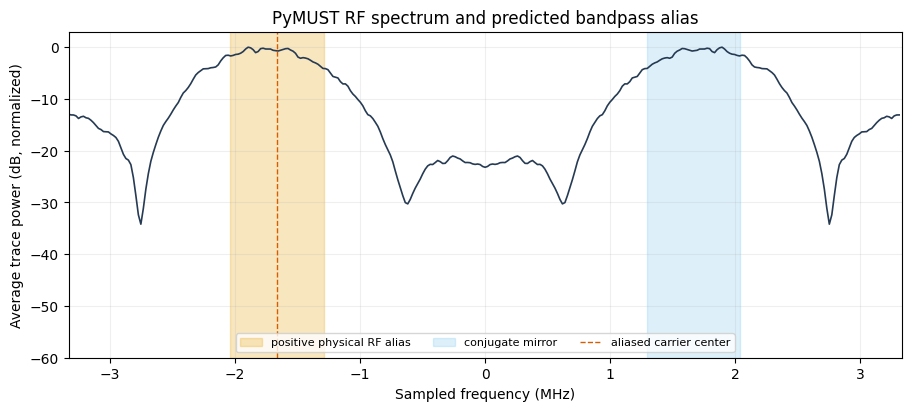

Saved: /content/realtime-beamforming-lab/results/exercise4-pymust-alias-spectrum.png


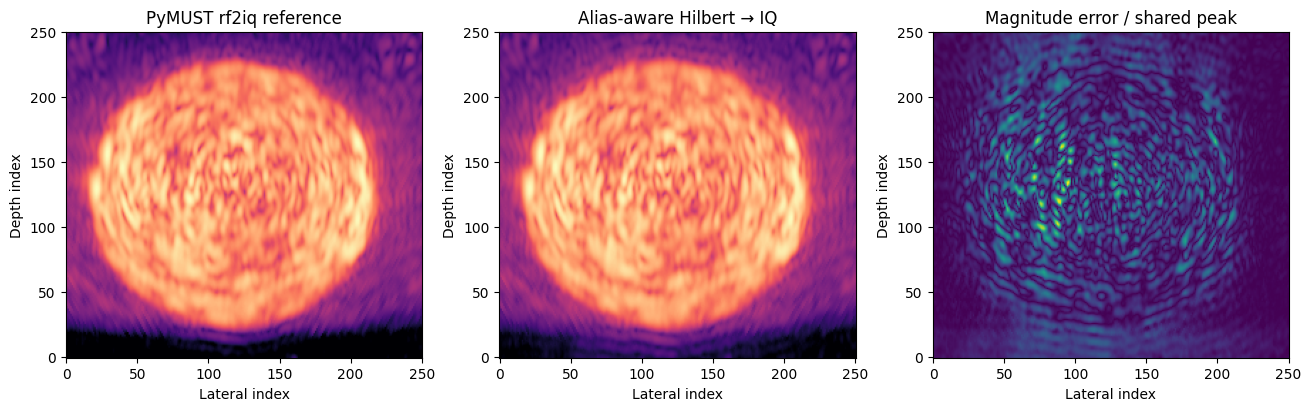

Alias-aware B-mode metrics vs PyMUST rf2iq: {'normalized_l2_error': 0.04106476634109082, 'max_abs_error_over_shared_peak': 0.07847544861424016, 'correlation': 0.998231264727839}
Standard-Hilbert B-mode metrics vs PyMUST rf2iq: {'normalized_l2_error': 0.4971012998524057, 'max_abs_error_over_shared_peak': 0.6329251347732746, 'correlation': 0.6746225582486668}
Saved: /content/realtime-beamforming-lab/results/exercise4-pymust-alias-hilbert-reconstruction.png


In [25]:
# PyMUST-only experiment: choose the physical positive-RF lobe despite its negative sampled alias.
pymust_dataset = datasets["pymust"]
pymust_meta_for_alias = pymust_dataset["meta"]
pymust_rf_matrix = pymust_dataset["rf_matrix"]
alias_frequency_hz, alias_power, alias_spectrum_summary = pymust_alias_spectrum(
    pymust_rf_matrix, pymust_meta_for_alias
)
alias_iq = alias_aware_hilbert_to_baseband(pymust_rf_matrix, pymust_meta_for_alias)

import pymust
pymust_reference_iq = np.ascontiguousarray(
    pymust.rf2iq(pymust_rf_matrix, pymust_dataset["pymust_params"]), dtype=np.complex64
)
interior = slice(32, -32)
phase_projection = np.vdot(pymust_reference_iq[interior], alias_iq[interior])

# A known-phase synthetic carrier checks mixer sign, t0, and the positive-physical-frequency choice.
_synth_n = pymust_rf_matrix.shape[0]
_synth_fs = pymust_meta_for_alias["fs_hz"]
_synth_fc = pymust_meta_for_alias["fc_hz"]
_synth_t0 = pymust_meta_for_alias["t0_s"]
_synth_t = np.arange(_synth_n, dtype=np.float64) / _synth_fs + _synth_t0
_synth_phases = np.asarray([0.0, 0.37, -0.82, 1.41], dtype=np.float64)
_synth_env = (0.8 + 0.15 * np.cos(2.0 * np.pi * 120_000.0 * (_synth_t - _synth_t0))).reshape(-1, 1)
_synth_rf = np.ascontiguousarray(
    _synth_env * np.cos(2.0 * np.pi * _synth_fc * _synth_t.reshape(-1, 1) + _synth_phases.reshape(1, -1)),
    dtype=np.float32,
)
_synth_iq = alias_aware_hilbert_to_baseband(_synth_rf, pymust_meta_for_alias)
_synth_iq_truth = _synth_env * np.exp(1j * _synth_phases.reshape(1, -1))

alias_report = {
    "purpose": "PyMUST-specific accuracy and reconstruction diagnostic; excluded from CPU/GPU timing benchmark.",
    "method": "FFT-mask the negative sampled-frequency band corresponding to positive physical RF, double it to form analytic RF, mix with exp(-j*2*pi*fc*(n/fs+t0)), then apply the PyMUST fifth-order Butterworth filtfilt cutoff.",
    "spectrum": alias_spectrum_summary,
    "phase_validation": {
        "synthetic_known_phase_center_nrmse": normalized_l2(_synth_iq_truth[interior], _synth_iq[interior]),
        "synthetic_trace_phases_rad": _synth_phases.tolist(),
        "trimmed_samples_each_edge": 32,
    },
    "iq_vs_pymust_rf2iq": {
        "full_nrmse": normalized_l2(pymust_reference_iq, alias_iq),
        "interior_nrmse": normalized_l2(pymust_reference_iq[interior], alias_iq[interior]),
        "interior_global_phase_error_rad": float(np.angle(phase_projection)),
        "interior_magnitude_ratio": float(
            np.linalg.norm(alias_iq[interior]) / max(np.linalg.norm(pymust_reference_iq[interior]), np.finfo(np.float64).tiny)
        ),
    },
}

report["pymust_alias_aware_diagnostic"] = alias_report
report["datasets"]["pymust"]["accuracy"]["alias_aware_hilbert_iq_vs_pymust_rf2iq_nrmse"] = alias_report["iq_vs_pymust_rf2iq"]["full_nrmse"]
report["datasets"]["pymust"]["accuracy"]["alias_aware_hilbert_iq_vs_pymust_rf2iq_interior_nrmse"] = alias_report["iq_vs_pymust_rf2iq"]["interior_nrmse"]

print("PyMUST alias-aware band estimate:")
print(f"  physical RF: {alias_spectrum_summary['physical_band_hz'][0] / 1e6:.3f}–{alias_spectrum_summary['physical_band_hz'][1] / 1e6:.3f} MHz")
print(f"  sampled alias: {alias_spectrum_summary['selected_alias_band_hz'][0] / 1e6:.3f}–{alias_spectrum_summary['selected_alias_band_hz'][1] / 1e6:.3f} MHz")
print(f"  averaged-spectrum peak: {alias_spectrum_summary['measured_negative_lobe_peak_hz'] / 1e6:.3f} MHz")
print(f"  measured contiguous −6 dB span: {alias_spectrum_summary['measured_negative_lobe_contiguous_minus6db_hz'][0] / 1e6:.3f}–{alias_spectrum_summary['measured_negative_lobe_contiguous_minus6db_hz'][1] / 1e6:.3f} MHz")
print(f"  power in predicted alias pair: {100 * alias_spectrum_summary['power_fraction_in_nominal_alias_pair']:.2f}%")
print("  synthetic known-phase interior NRMSE:", alias_report["phase_validation"]["synthetic_known_phase_center_nrmse"])
print("  alias-IQ vs pymust.rf2iq full/interior NRMSE:", alias_report["iq_vs_pymust_rf2iq"]["full_nrmse"], alias_report["iq_vs_pymust_rf2iq"]["interior_nrmse"])

import matplotlib.pyplot as plt
_alias_peak = float(np.max(alias_power))
_alias_db = 10.0 * np.log10(np.maximum(alias_power, _alias_peak * 1e-12) / _alias_peak)
_alias_band = pymust_alias_band(pymust_meta_for_alias)
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.plot(alias_frequency_hz / 1e6, _alias_db, color="#263b53", linewidth=1.2)
ax.axvspan(*[v / 1e6 for v in _alias_band["selected_alias_band_hz"]], color="#e69f00", alpha=0.25, label="positive physical RF alias")
ax.axvspan(*[v / 1e6 for v in _alias_band["mirror_alias_band_hz"]], color="#56b4e9", alpha=0.2, label="conjugate mirror")
ax.axvline(_alias_band["alias_center_hz"] / 1e6, color="#d55e00", linestyle="--", linewidth=1, label="aliased carrier center")
ax.set(xlim=(-_alias_band["nyquist_hz"] / 1e6, _alias_band["nyquist_hz"] / 1e6), ylim=(-60, 3), xlabel="Sampled frequency (MHz)", ylabel="Average trace power (dB, normalized)", title="PyMUST RF spectrum and predicted bandpass alias")
ax.grid(alpha=0.2)
ax.legend(loc="lower center", ncol=3, fontsize=8)
alias_spectrum_plot_path = RESULTS_DIR / "exercise4-pymust-alias-spectrum.png"
fig.savefig(alias_spectrum_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", alias_spectrum_plot_path)

if RUN_BEAMFORM_IMAGE_CHECKS:
    pymust_alias_setup = pymust_beamform_setup(pymust_dataset["pymust_params"])
    alias_image, alias_upload_ms, alias_beamform_ms, alias_image_d2h_ms = render_pymust(
        alias_iq, pymust_dataset, pymust_meta_for_alias["fc_hz"], pymust_alias_setup
    )
    reference_image = image_outputs["pymust"]["baseband"]["cpu_conversion"]
    standard_hilbert_image = image_outputs["pymust"]["hilbert"]["cpu_conversion"]
    alias_report["beamformed_image_vs_pymust_rf2iq"] = image_metrics(reference_image, alias_image)
    alias_report["standard_hilbert_image_vs_pymust_rf2iq"] = image_metrics(reference_image, standard_hilbert_image)
    image_outputs["pymust"]["alias_aware_hilbert"] = {"cpu_conversion": alias_image}
    alias_report["beamforming_ms"] = alias_beamform_ms
    alias_report["iq_upload_ms"] = alias_upload_ms
    alias_report["image_download_ms"] = alias_image_d2h_ms
    report["pymust_alias_aware_diagnostic"] = alias_report
    report["datasets"]["pymust"]["accuracy"]["alias_aware_hilbert_bmode_vs_pymust_rf2iq"] = alias_report["beamformed_image_vs_pymust_rf2iq"]

    _shared_peak = max(float(np.max(reference_image)), float(np.max(alias_image)), np.finfo(np.float64).tiny)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    for axis, image, title in (
        (axes[0], reference_image, "PyMUST rf2iq reference"),
        (axes[1], alias_image, "Alias-aware Hilbert → IQ"),
    ):
        axis.imshow(20 * np.log10(np.maximum(image / _shared_peak, 1e-4)).T, origin="lower", cmap="magma", vmin=-40, vmax=0, aspect="auto")
        axis.set_title(title)
        axis.set_xlabel("Lateral index")
        axis.set_ylabel("Depth index")
    axes[2].imshow((np.abs(alias_image - reference_image) / _shared_peak).T, origin="lower", cmap="viridis", aspect="auto")
    axes[2].set_title("Magnitude error / shared peak")
    axes[2].set_xlabel("Lateral index")
    axes[2].set_ylabel("Depth index")
    alias_image_plot_path = RESULTS_DIR / "exercise4-pymust-alias-hilbert-reconstruction.png"
    fig.savefig(alias_image_plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Alias-aware B-mode metrics vs PyMUST rf2iq:", alias_report["beamformed_image_vs_pymust_rf2iq"])
    print("Standard-Hilbert B-mode metrics vs PyMUST rf2iq:", alias_report["standard_hilbert_image_vs_pymust_rf2iq"])
    print("Saved:", alias_image_plot_path)
else:
    print("Beamformed alias-aware image check skipped because RUN_BEAMFORM_IMAGE_CHECKS is False.")


## 5. PICMUS angle-count scaling

PICMUS provides 75 measured transmit angles. This sweep progressively includes 1, 2, 4, 8, 16, 32, and 75 angles while retaining every receive channel and complete fast-time trace for each selected angle. CPU workers partition the resulting channel-angle trace columns; the GPU processes the same matrix. The plot compares conversion time by workload size, and the report records exact input/output payload sizes. GPU compute events exclude transfers; H2D and D2H are recorded separately and included in a one-shot estimate. The full worker-count sweep and memory sampling above still use all 75 angles.


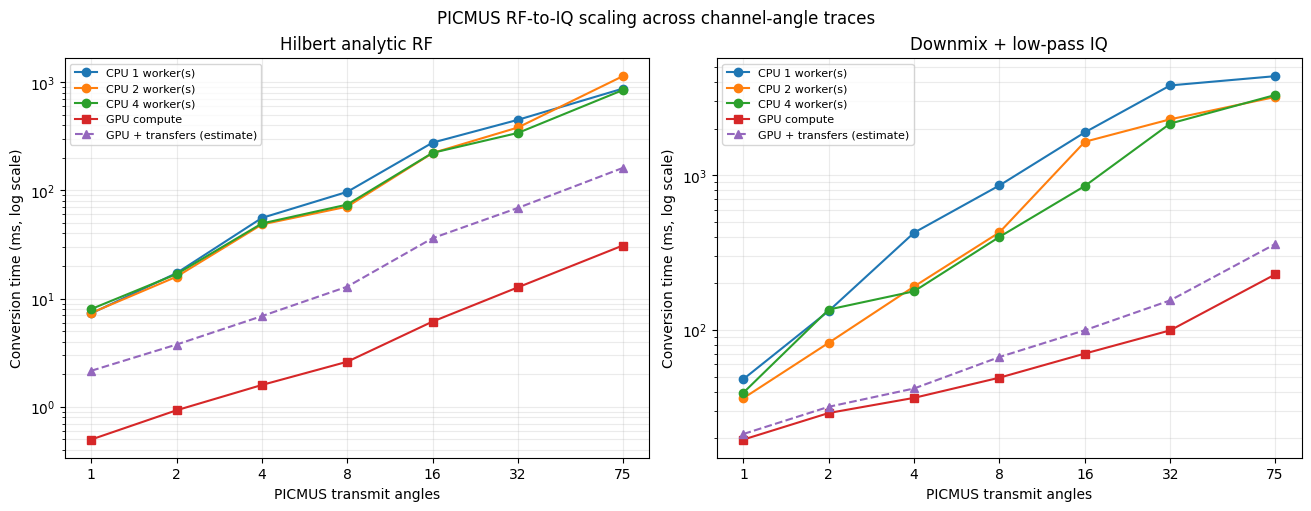

Angle scaling points: 7
Traces at 75 angles: 9600
Saved: /content/realtime-beamforming-lab/results/exercise4-picmus-angle-scaling.png


In [26]:
if RUN_PICMUS_ANGLE_SCALING:
    picmus_dataset = datasets["picmus"]
    picmus_raw = picmus_dataset["raw"]  # samples × receive channels × angles × frames
    n_samples, n_elements, n_angles, n_frames = picmus_raw.shape
    angle_counts = sorted({min(n_angles, count) for count in (1, 2, 4, 8, 16, 32, 75)})
    scaling_workers = CPU_WORKERS if RUN_CPU_WORKER_SWEEP else (1,)
    angle_scaling = {
        "dataset": picmus_dataset["label"],
        "source_shape": list(picmus_raw.shape),
        "angle_counts": angle_counts,
        "cpu_workers": list(scaling_workers),
        "warmup_runs": WARMUP_RUNS,
        "measured_runs": MEASURED_RUNS,
        "timing_scope": "CPU conversion p50; GPU device-event conversion p50; H2D and D2H measured separately.",
        "points": [],
    }
    for angle_count in angle_counts:
        rf_subset = np.ascontiguousarray(
            picmus_raw[:, :, :angle_count, :].reshape(n_samples, -1), dtype=np.float32
        )
        device_subset, h2d_subset_ms = prepare_gpu_input(rf_subset)
        point = {
            "angles": int(angle_count),
            "receive_channels": int(n_elements),
            "frames": int(n_frames),
            "independent_traces": int(rf_subset.shape[1]),
            "fast_time_samples": int(n_samples),
            "input_nbytes": int(rf_subset.nbytes),
            "output_nbytes_complex64": int(rf_subset.size * np.dtype(np.complex64).itemsize),
            "h2d_ms": float(h2d_subset_ms),
            "methods": {},
        }
        for method in ("hilbert", "baseband"):
            cpu_by_worker = {}
            for worker_count in scaling_workers:
                timing, _ = time_cpu(method, rf_subset, picmus_dataset["meta"], worker_count)
                cpu_by_worker[str(worker_count)] = timing
            gpu_timing, gpu_output = time_gpu(method, device_subset, picmus_dataset["meta"])
            d2h_started = time.perf_counter_ns()
            gpu_output_host = cp.asnumpy(gpu_output)
            cp.cuda.Device().synchronize()
            d2h_subset_ms = (time.perf_counter_ns() - d2h_started) / 1e6
            point["methods"][method] = {
                "cpu_workers": cpu_by_worker,
                "gpu": {
                    "device_event": gpu_timing["device_event"],
                    "wall": gpu_timing["wall"],
                    "cold_first_call_wall_ms": gpu_timing["cold_first_call_wall_ms"],
                    "h2d_ms": float(h2d_subset_ms),
                    "d2h_ms": float(d2h_subset_ms),
                    "transfer_inclusive_one_shot_ms_estimate": float(
                        h2d_subset_ms + gpu_timing["wall"]["p50_ms"] + d2h_subset_ms
                    ),
                },
            }
            del gpu_output, gpu_output_host
            cp.get_default_memory_pool().free_all_blocks()
        angle_scaling["points"].append(point)
        del rf_subset, device_subset
        gc.collect()

    report["picmus_angle_scaling"] = angle_scaling

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    for ax, method in zip(axes, ("hilbert", "baseband")):
        for worker_count in scaling_workers:
            ax.plot(
                angle_counts,
                [point["methods"][method]["cpu_workers"][str(worker_count)]["p50_ms"]
                 for point in angle_scaling["points"]],
                marker="o", label=f"CPU {worker_count} worker(s)",
            )
        ax.plot(
            angle_counts,
            [point["methods"][method]["gpu"]["device_event"]["p50_ms"]
             for point in angle_scaling["points"]],
            marker="s", label="GPU compute",
        )
        ax.plot(
            angle_counts,
            [point["methods"][method]["gpu"]["transfer_inclusive_one_shot_ms_estimate"]
             for point in angle_scaling["points"]],
            marker="^", linestyle="--", label="GPU + transfers (estimate)",
        )
        ax.set_xscale("log", base=2)
        ax.set_xticks(angle_counts, [str(count) for count in angle_counts])
        ax.set_xlabel("PICMUS transmit angles")
        ax.set_ylabel("Conversion time (ms, log scale)")
        ax.set_yscale("log")
        ax.set_title("Hilbert analytic RF" if method == "hilbert" else "Downmix + low-pass IQ")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle("PICMUS RF-to-IQ scaling across channel-angle traces")
    angle_scaling_plot_path = RESULTS_DIR / "exercise4-picmus-angle-scaling.png"
    fig.savefig(angle_scaling_plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Angle scaling points:", len(angle_scaling["points"]))
    print("Traces at 75 angles:", angle_scaling["points"][-1]["independent_traces"])
    print("Saved:", angle_scaling_plot_path)
else:
    report["picmus_angle_scaling"] = {"run": False, "reason": "Disabled in configuration."}
    print("PICMUS angle-count scaling disabled.")


To extend beyond the 75-angle recording, this cell creates a reproducible PICMUS-shaped RF input with a known low-frequency envelope and carrier at four times the measured 9,600-trace workload (38,400 complete traces). It reports total CPU and GPU timing, transfer-inclusive GPU cost, speedup, scale efficiency relative to measured PICMUS, and numerical agreement with CPU output and known baseband IQ. CPU conversion is processed in fixed trace chunks. The full workload is divided into four 9,600-trace batches; each is uploaded, converted, downloaded, and released before the next batch. This bounds peak GPU working memory while timing the full fourfold volume.


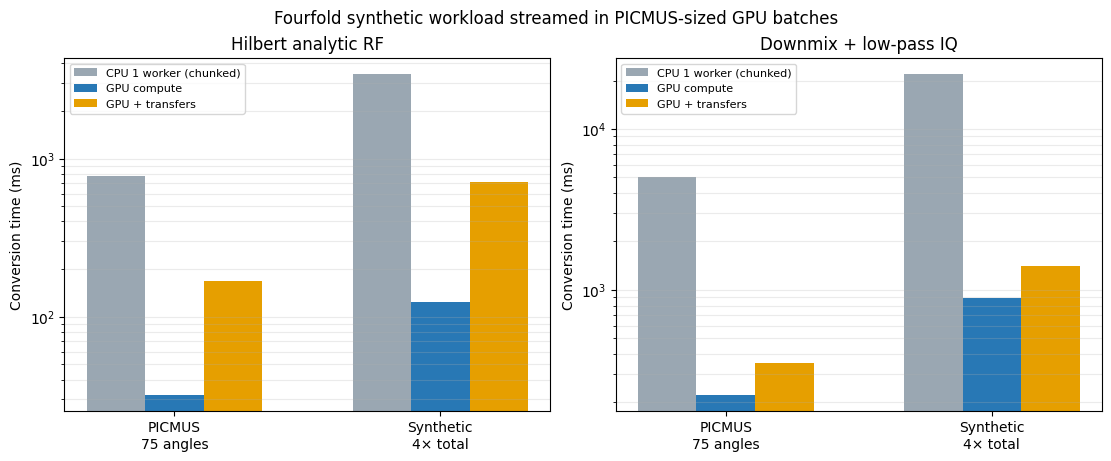

Synthetic workload shape: [3328, 38400]
GPU processes 4 batches of at most 9600 traces; total scale: 4 x PICMUS.
hilbert: CPU chunked=3425.2 ms; GPU compute total=124.0 ms; GPU + transfers total≈706.7 ms; GPU scale efficiency=1.03; CPU/GPU NRMSE=2.24e-07; known-IQ NRMSE=0.000155
baseband: CPU chunked=21944.0 ms; GPU compute total=896.3 ms; GPU + transfers total≈1414.6 ms; GPU scale efficiency=0.99; CPU/GPU NRMSE=1.64e-10; known-IQ NRMSE=0.000153
Saved: /content/realtime-beamforming-lab/results/exercise4-synthetic-scale.png


In [27]:
if RUN_SYNTHETIC_SCALE_CASE:
    picmus_dataset = datasets["picmus"]
    baseline_rf = picmus_dataset["rf_matrix"]
    n_samples, baseline_traces = baseline_rf.shape
    n_traces = baseline_traces * SYNTHETIC_SCALE_MULTIPLIER
    fs_hz = picmus_dataset["meta"]["fs_hz"]
    fc_hz = picmus_dataset["meta"]["fc_hz"]
    t = np.arange(n_samples, dtype=np.float32) / np.float32(fs_hz)
    trace_phase = np.linspace(0.0, 2.0 * np.pi, n_traces, endpoint=False, dtype=np.float32)

    # Keep only the synthetic RF on the host; create and release each GPU batch in turn.
    synthetic_rf = np.empty((n_samples, n_traces), dtype=np.float32)
    generation_chunk_traces = 256
    for first_trace in range(0, n_traces, generation_chunk_traces):
        last_trace = min(n_traces, first_trace + generation_chunk_traces)
        phases = trace_phase[None, first_trace:last_trace]
        envelope_chunk = 0.7 + 0.3 * np.cos(
            2.0 * np.pi * np.float32(150_000.0) * t[:, None] + phases
        )
        carrier_chunk = np.cos(
            2.0 * np.pi * np.float32(fc_hz) * t[:, None] + phases
        )
        synthetic_rf[:, first_trace:last_trace] = envelope_chunk * carrier_chunk
        del phases, envelope_chunk, carrier_chunk

    synthetic_meta = {"fs_hz": fs_hz, "fc_hz": fc_hz, "t0_s": 0.0, "bandwidth_percent": None}
    cpu_chunk_traces = 256
    gpu_batch_traces = baseline_traces

    def cpu_convert_chunked(method, rf_matrix, meta, chunk_traces=cpu_chunk_traces):
        output = np.empty(rf_matrix.shape, dtype=np.complex64)
        for first_trace in range(0, rf_matrix.shape[1], chunk_traces):
            last_trace = min(rf_matrix.shape[1], first_trace + chunk_traces)
            output[:, first_trace:last_trace] = cpu_convert(
                method, rf_matrix[:, first_trace:last_trace], meta
            )
        return output

    def time_cpu_chunked(method, rf_matrix, meta, chunk_traces=cpu_chunk_traces):
        for _ in range(WARMUP_RUNS):
            warm_output = cpu_convert_chunked(method, rf_matrix, meta, chunk_traces)
            del warm_output
        samples, latest = [], None
        for _ in range(MEASURED_RUNS):
            started = time.perf_counter_ns()
            current = cpu_convert_chunked(method, rf_matrix, meta, chunk_traces)
            samples.append((time.perf_counter_ns() - started) / 1e6)
            if latest is not None:
                del latest
            latest = current
        return percentile_summary(samples), latest

    def add_nrmse_energy(reference, candidate, reference_energy, error_energy, row_chunk=64):
        for lo in range(0, reference.shape[0], row_chunk):
            hi = min(reference.shape[0], lo + row_chunk)
            ref_chunk = np.asarray(reference[lo:hi], dtype=np.complex128)
            got_chunk = np.asarray(candidate[lo:hi], dtype=np.complex128)
            reference_energy += float(np.vdot(ref_chunk.ravel(), ref_chunk.ravel()).real)
            difference = ref_chunk - got_chunk
            error_energy += float(np.vdot(difference.ravel(), difference.ravel()).real)
        return reference_energy, error_energy

    def add_known_iq_energy(candidate, method, batch_phases, ref_energy, error_energy, row_chunk=64):
        phasor = np.exp(1j * batch_phases).astype(np.complex64)
        for lo in range(64, n_samples - 64, row_chunk):
            hi = min(n_samples - 64, lo + row_chunk)
            envelope_phase = (
                2.0 * np.pi * np.float32(150_000.0) * t[lo:hi, None]
                + batch_phases[None, :]
            )
            envelope = 0.7 + 0.3 * np.cos(envelope_phase)
            truth = np.asarray(envelope * phasor[None, :], dtype=np.complex128)
            got = candidate[lo:hi]
            if method == "hilbert":
                demod = np.exp(-2j * np.pi * fc_hz * t[lo:hi]).astype(np.complex64)
                got = got * demod[:, None]
            got = np.asarray(got, dtype=np.complex128)
            ref_energy += float(np.vdot(truth.ravel(), truth.ravel()).real)
            difference = truth - got
            error_energy += float(np.vdot(difference.ravel(), difference.ravel()).real)
            del envelope_phase, envelope, truth, got, difference
        return ref_energy, error_energy

    synthetic_results = {
        "shape": [n_samples, n_traces],
        "scale_multiplier_vs_picmus": int(SYNTHETIC_SCALE_MULTIPLIER),
        "baseline_picmus_traces": int(baseline_traces),
        "independent_traces": int(n_traces),
        "raw_nbytes": int(synthetic_rf.nbytes),
        "output_nbytes_complex64": int(synthetic_rf.size * np.dtype(np.complex64).itemsize),
        "cpu_trace_chunk_size": int(cpu_chunk_traces),
        "gpu_batch_trace_size": int(gpu_batch_traces),
        "gpu_batch_count": int(np.ceil(n_traces / gpu_batch_traces)),
        "cpu_timing_scope": "CPU conversion is processed in fixed trace chunks; full-workload timing includes chunk assembly.",
        "gpu_timing_scope": "GPU input is uploaded and converted one PICMUS-sized batch at a time; the full workload timing sums batches.",
        "measured_picmus_baseline": {},
        "methods": {},
    }

    for method in ("hilbert", "baseband"):
        baseline_method = report["datasets"]["picmus"]["methods"][method]
        baseline_cpu_timing, baseline_cpu_output = time_cpu_chunked(
            method, baseline_rf, picmus_dataset["meta"]
        )
        del baseline_cpu_output
        gc.collect()
        baseline_gpu_ms = float(baseline_method["gpu"]["device_event"]["p50_ms"])
        synthetic_results["measured_picmus_baseline"][method] = {
            "cpu_1_worker_chunked": baseline_cpu_timing,
            "gpu_compute_event_p50_ms": baseline_gpu_ms,
            "gpu_transfer_inclusive_ms": float(
                baseline_method["gpu"]["transfer_inclusive_one_shot_ms_estimate"]
            ),
        }

        cpu_samples = np.zeros(MEASURED_RUNS, dtype=np.float64)
        gpu_wall_samples = np.zeros(MEASURED_RUNS, dtype=np.float64)
        gpu_device_samples = np.zeros(MEASURED_RUNS, dtype=np.float64)
        h2d_total_ms = 0.0
        d2h_total_ms = 0.0
        cpu_gpu_reference_energy = cpu_gpu_error_energy = 0.0
        known_reference_energy = known_error_energy = 0.0
        cold_first_call_wall_ms = None

        for batch_index, first_trace in enumerate(range(0, n_traces, gpu_batch_traces)):
            last_trace = min(n_traces, first_trace + gpu_batch_traces)
            rf_batch = np.ascontiguousarray(synthetic_rf[:, first_trace:last_trace])
            batch_phases = trace_phase[first_trace:last_trace]

            cpu_timing, cpu_value = time_cpu_chunked(method, rf_batch, synthetic_meta)
            cpu_samples += np.asarray(cpu_timing["samples_ms"], dtype=np.float64)
            known_reference_energy, known_error_energy = add_known_iq_energy(
                cpu_value, method, batch_phases, known_reference_energy, known_error_energy
            )

            gpu_input, batch_h2d_ms = prepare_gpu_input(rf_batch)
            h2d_total_ms += float(batch_h2d_ms)
            gpu_timing, gpu_value = time_gpu(method, gpu_input, synthetic_meta)
            if batch_index == 0:
                cold_first_call_wall_ms = float(gpu_timing["cold_first_call_wall_ms"])
            gpu_wall_samples += np.asarray(gpu_timing["wall"]["samples_ms"], dtype=np.float64)
            gpu_device_samples += np.asarray(
                gpu_timing["device_event"]["samples_ms"], dtype=np.float64
            )
            d2h_started = time.perf_counter_ns()
            gpu_value_host = cp.asnumpy(gpu_value)
            cp.cuda.Device().synchronize()
            d2h_total_ms += (time.perf_counter_ns() - d2h_started) / 1e6
            cpu_gpu_reference_energy, cpu_gpu_error_energy = add_nrmse_energy(
                cpu_value, gpu_value_host, cpu_gpu_reference_energy, cpu_gpu_error_energy
            )

            del rf_batch, batch_phases, cpu_value, gpu_input, gpu_value, gpu_value_host
            cp.get_default_memory_pool().free_all_blocks()
            gc.collect()

        cpu_timing = percentile_summary(cpu_samples.tolist())
        gpu_wall = percentile_summary(gpu_wall_samples.tolist())
        gpu_device = percentile_summary(gpu_device_samples.tolist())
        transfer_inclusive_ms = float(h2d_total_ms + gpu_wall["p50_ms"] + d2h_total_ms)
        cpu_ms = float(cpu_timing["p50_ms"])
        gpu_compute_ms = float(gpu_device["p50_ms"])
        baseline_cpu_ms = float(baseline_cpu_timing["p50_ms"])
        synthetic_results["methods"][method] = {
            "cpu_1_worker_chunked": cpu_timing,
            "gpu": {
                "device_event": gpu_device,
                "wall": gpu_wall,
                "cold_first_call_wall_ms": cold_first_call_wall_ms,
                "h2d_ms_all_batches_once": h2d_total_ms,
                "d2h_ms_all_batches_once": d2h_total_ms,
                "transfer_inclusive_total_workload_ms": transfer_inclusive_ms,
            },
            "cpu_vs_gpu_nrmse": float(
                np.sqrt(cpu_gpu_error_energy / cpu_gpu_reference_energy)
            ) if cpu_gpu_reference_energy else 0.0,
            "cpu_vs_known_baseband_iq_nrmse_center": float(
                np.sqrt(known_error_energy / known_reference_energy)
            ) if known_reference_energy else 0.0,
            "gpu_compute_speedup_vs_cpu_1_worker_chunked": float(cpu_ms / gpu_compute_ms) if gpu_compute_ms else None,
            "gpu_transfer_inclusive_speedup_vs_cpu_1_worker_chunked": float(cpu_ms / transfer_inclusive_ms) if transfer_inclusive_ms else None,
            "gpu_workload_scale_efficiency_vs_real_picmus": float(
                SYNTHETIC_SCALE_MULTIPLIER * baseline_gpu_ms / gpu_compute_ms
            ) if gpu_compute_ms else None,
            "cpu_workload_scale_efficiency_vs_real_picmus": float(
                SYNTHETIC_SCALE_MULTIPLIER * baseline_cpu_ms / cpu_ms
            ) if cpu_ms else None,
            "output_nbytes_complex64": int(n_samples * n_traces * np.dtype(np.complex64).itemsize),
        }

    report["synthetic_scale_case"] = synthetic_results
    del synthetic_rf, baseline_rf, t, trace_phase
    gc.collect()
    cp.get_default_memory_pool().free_all_blocks()

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
    for ax, method in zip(axes, ("hilbert", "baseband")):
        baseline = synthetic_results["measured_picmus_baseline"][method]
        scaled = synthetic_results["methods"][method]
        labels = ["PICMUS\n75 angles", "Synthetic\n4× total"]
        ax.bar(np.arange(2) - 0.22, [baseline["cpu_1_worker_chunked"]["p50_ms"], scaled["cpu_1_worker_chunked"]["p50_ms"]], width=0.22, color="#9aa7b2", label="CPU 1 worker (chunked)")
        ax.bar(np.arange(2), [baseline["gpu_compute_event_p50_ms"], scaled["gpu"]["device_event"]["p50_ms"]], width=0.22, color="#2878b5", label="GPU compute")
        ax.bar(np.arange(2) + 0.22, [baseline["gpu_transfer_inclusive_ms"], scaled["gpu"]["transfer_inclusive_total_workload_ms"]], width=0.22, color="#e69f00", label="GPU + transfers")
        ax.set_xticks(np.arange(2), labels)
        ax.set_ylabel("Conversion time (ms)")
        ax.set_yscale("log")
        ax.set_title("Hilbert analytic RF" if method == "hilbert" else "Downmix + low-pass IQ")
        ax.grid(axis="y", which="both", alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle("Fourfold synthetic workload streamed in PICMUS-sized GPU batches")
    synthetic_plot_path = RESULTS_DIR / "exercise4-synthetic-scale.png"
    fig.savefig(synthetic_plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Synthetic workload shape:", synthetic_results["shape"])
    print(
        "GPU processes", synthetic_results["gpu_batch_count"], "batches of at most",
        gpu_batch_traces, "traces; total scale:", SYNTHETIC_SCALE_MULTIPLIER, "x PICMUS."
    )
    for method, values in synthetic_results["methods"].items():
        print(
            f"{method}: CPU chunked={values['cpu_1_worker_chunked']['p50_ms']:.1f} ms; "
            f"GPU compute total={values['gpu']['device_event']['p50_ms']:.1f} ms; "
            f"GPU + transfers total≈{values['gpu']['transfer_inclusive_total_workload_ms']:.1f} ms; "
            f"GPU scale efficiency={values['gpu_workload_scale_efficiency_vs_real_picmus']:.2f}; "
            f"CPU/GPU NRMSE={values['cpu_vs_gpu_nrmse']:.3g}; "
            f"known-IQ NRMSE={values['cpu_vs_known_baseband_iq_nrmse_center']:.3g}"
        )
    print("Saved:", synthetic_plot_path)
else:
    report["synthetic_scale_case"] = {"run": False, "reason": "Disabled in configuration."}
    print("Deterministic synthetic scale case disabled.")


## 7. Save the report and review the comparisons

The JSON report includes dataset fingerprints, software/runtime versions, timing samples, worker counts, angle-scaling points, transfer costs, sampled memory deltas, synthetic workload scaling efficiency, and accuracy metrics. Large converted RF arrays are not saved; the report remains small and the source data stays in its upstream cache.


In [28]:
import json

report_path = RESULTS_DIR / "exercise4-rf-to-iq.json"
report_path.write_text(json.dumps(report, indent=2, default=lambda value: value.item() if isinstance(value, np.generic) else str(value)) + "\n")
print("Saved:", report_path)

try:
    _git_root = next(parent for parent in (ROOT, *ROOT.parents) if (parent / ".git").exists())
    _git_rev = subprocess.run(["git", "rev-parse", "HEAD"], cwd=_git_root, text=True, capture_output=True, check=True).stdout.strip()
    report["git_revision"] = _git_rev
    report_path.write_text(json.dumps(report, indent=2, default=lambda value: value.item() if isinstance(value, np.generic) else str(value)) + "\n")
    print("Git revision:", _git_rev)
except (StopIteration, subprocess.CalledProcessError):
    print("Git revision unavailable from the kernel working directory.")


Saved: /content/realtime-beamforming-lab/results/exercise4-rf-to-iq.json
Git revision: a316205300f0ff437522f4ba8def5c35866f2695


,Dataset,Method,CPU 1 worker p50 (ms),CPU best p50 (ms),Best workers,GPU event p50 (ms),GPU transfer-inclusive (ms),CPU/GPU signal NRMSE,Host RSS delta (MiB),GPU pool delta (MiB)
0,pymust,hilbert,60.7505,53.4347,2,1.2441,6.0097,0.0,0.0039,20.8750
1,pymust,baseband,353.1747,145.9204,4,34.9293,39.2364,0.0,79.8164,116.4624
2,picmus,hilbert,842.4166,791.2506,2,31.9189,168.4545,0.0,731.2617,487.5000
3,picmus,baseband,4460.0765,3317.3647,4,222.2531,353.7079,0.0,1965.8359,2468.6870


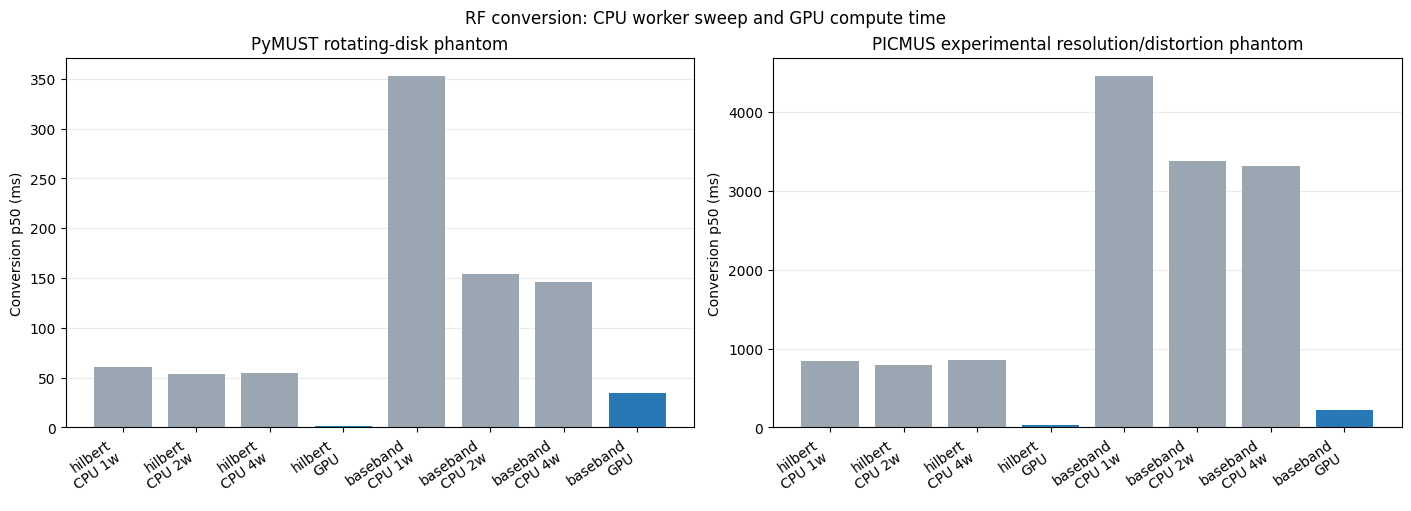

Saved: /content/realtime-beamforming-lab/results/exercise4-conversion-timing.png


In [29]:
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

rows = []
for dataset_name, dataset_result in report["datasets"].items():
    for method, method_result in dataset_result["methods"].items():
        worker_keys = [key for key in method_result["cpu_workers"] if key.isdigit()]
        best_worker = min(worker_keys, key=lambda key: method_result["cpu_workers"][key]["p50_ms"])
        rows.append({
            "Dataset": dataset_name, "Method": method,
            "CPU 1 worker p50 (ms)": method_result["cpu_workers"]["1"]["p50_ms"],
            "CPU best p50 (ms)": method_result["cpu_workers"][best_worker]["p50_ms"],
            "Best workers": int(best_worker),
            "GPU event p50 (ms)": method_result["gpu"]["device_event"]["p50_ms"],
            "GPU transfer-inclusive (ms)": method_result["gpu"]["transfer_inclusive_one_shot_ms_estimate"],
            "CPU/GPU signal NRMSE": dataset_result["accuracy"][f"{method}_cpu_vs_gpu_complex_nrmse"],
            "Host RSS delta (MiB)": method_result["cpu_workers"]["sampled_memory"]["sampled_host_rss_delta_mib"],
            "GPU pool delta (MiB)": method_result["gpu"]["sampled_memory"]["sampled_cupy_pool_peak_delta_mib"],
        })
summary = pd.DataFrame(rows)
display(summary.round(4))

fig, axes = plt.subplots(1, len(report["datasets"]), figsize=(14, 5), squeeze=False, constrained_layout=True)
for ax, (dataset_name, dataset_result) in zip(axes[0], report["datasets"].items()):
    methods = ("hilbert", "baseband")
    positions, labels, values, colors = [], [], [], []
    workers_to_plot = CPU_WORKERS if RUN_CPU_WORKER_SWEEP else (1,)
    slots_per_method = len(workers_to_plot) + 1
    for m_index, method in enumerate(methods):
        method_result = dataset_result["methods"][method]
        category_start = m_index * slots_per_method
        category_offset = 0
        for worker in workers_to_plot:
            key = str(worker)
            if key in method_result["cpu_workers"]:
                positions.append(category_start + category_offset)
                labels.append(f"{method}\nCPU {worker}w")
                values.append(method_result["cpu_workers"][key]["p50_ms"])
                colors.append("#9aa7b2")
                category_offset += 1
        positions.append(category_start + category_offset)
        labels.append(f"{method}\nGPU")
        values.append(method_result["gpu"]["device_event"]["p50_ms"])
        colors.append("#2878b5")
    bars = ax.bar(positions, values, color=colors, width=0.78)
    ax.set_xticks(positions, labels, rotation=35, ha="right")
    ax.set_ylabel("Conversion p50 (ms)")
    ax.set_title(dataset_result["label"])
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.suptitle("RF conversion: CPU worker sweep and GPU compute time")
timing_plot_path = RESULTS_DIR / "exercise4-conversion-timing.png"
fig.savefig(timing_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", timing_plot_path)


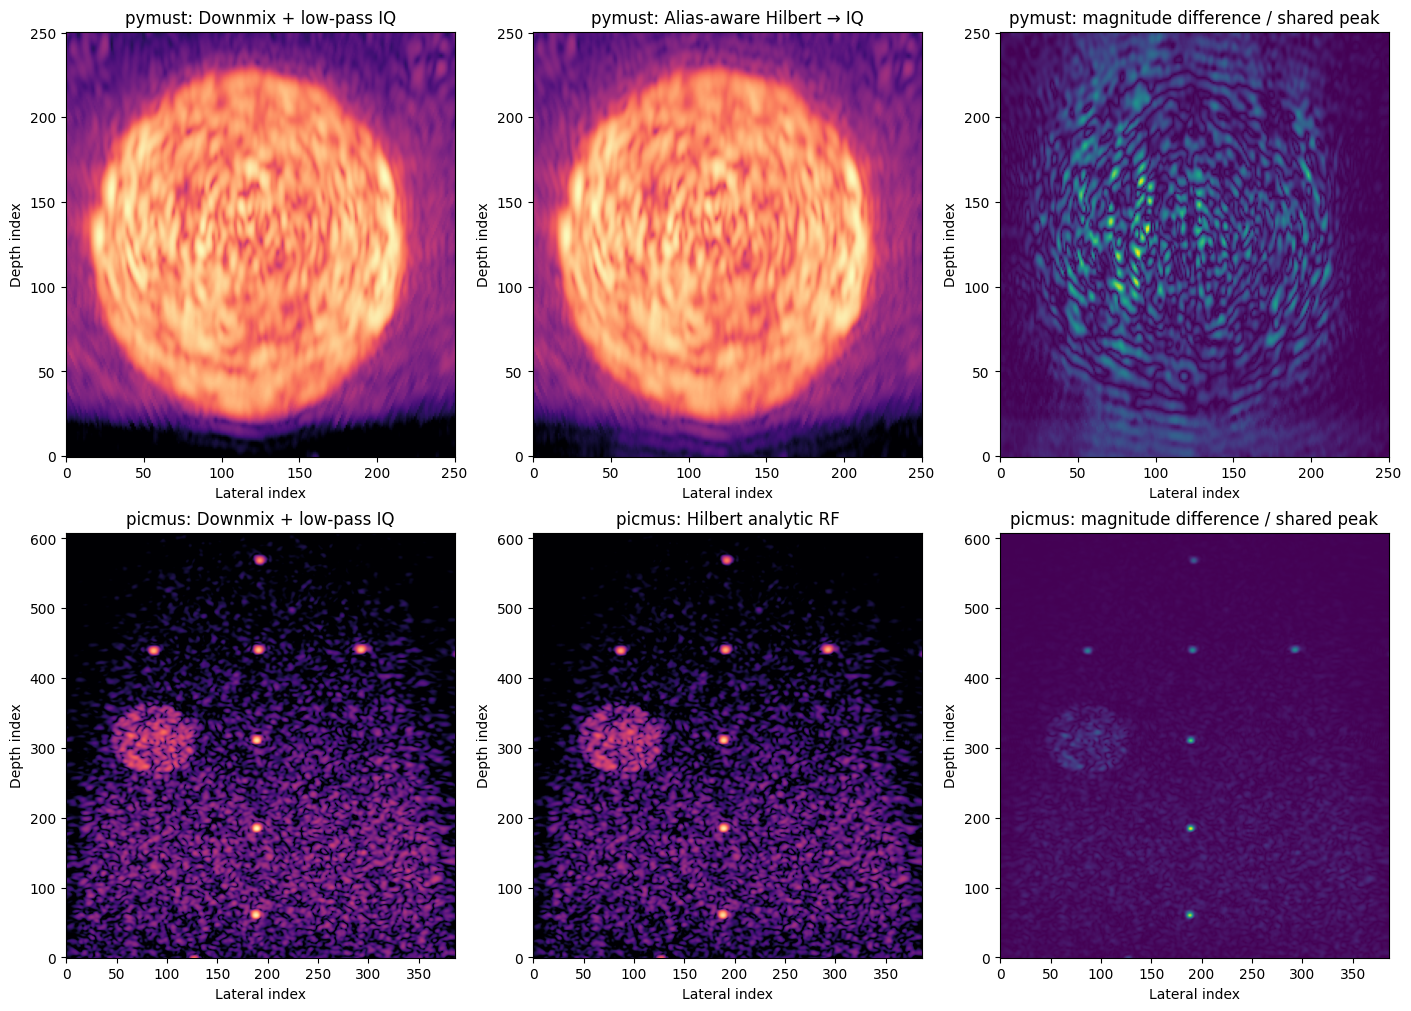

Saved: /content/realtime-beamforming-lab/results/exercise4-beamformed-image-comparison.png
pymust alias-aware Hilbert vs PyMUST rf2iq B-mode: {'normalized_l2_error': 0.04106476634109082, 'max_abs_error_over_shared_peak': 0.07847544861424016, 'correlation': 0.998231264727839}
pymust ordinary Hilbert remains diagnostic; see the separate alias diagnostic figure.
picmus CPU Hilbert vs baseband B-mode: {'normalized_l2_error': 0.20117358901493587, 'max_abs_error_over_shared_peak': 0.1608754071641685, 'correlation': 0.9993044340211438}


In [30]:
if RUN_BEAMFORM_IMAGE_CHECKS:
    fig, axes = plt.subplots(len(image_outputs), 3, figsize=(14, 5 * len(image_outputs)), squeeze=False, constrained_layout=True)
    for row, (dataset_name, outputs) in enumerate(image_outputs.items()):
        reference_image = outputs["baseband"]["cpu_conversion"]
        if dataset_name == "pymust" and "alias_aware_hilbert" in outputs:
            comparison_image = outputs["alias_aware_hilbert"]["cpu_conversion"]
            comparison_title = "Alias-aware Hilbert → IQ"
        else:
            comparison_image = outputs["hilbert"]["cpu_conversion"]
            comparison_title = "Hilbert analytic RF"
        peak = max(float(np.max(reference_image)), float(np.max(comparison_image)), np.finfo(np.float64).tiny)
        for col, (image, title) in enumerate(((reference_image, "Downmix + low-pass IQ"), (comparison_image, comparison_title))):
            axes[row, col].imshow(20 * np.log10(np.maximum(image / peak, 1e-4)).T, origin="lower", cmap="magma", vmin=-40, vmax=0, aspect="auto")
            axes[row, col].set_title(f"{dataset_name}: {title}")
            axes[row, col].set_xlabel("Lateral index")
            axes[row, col].set_ylabel("Depth index")
        difference = np.abs(reference_image - comparison_image) / peak
        axes[row, 2].imshow(difference.T, origin="lower", cmap="viridis", aspect="auto")
        axes[row, 2].set_title(f"{dataset_name}: magnitude difference / shared peak")
        axes[row, 2].set_xlabel("Lateral index")
        axes[row, 2].set_ylabel("Depth index")
    image_plot_path = RESULTS_DIR / "exercise4-beamformed-image-comparison.png"
    fig.savefig(image_plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", image_plot_path)
    for dataset_name, dataset_result in report["datasets"].items():
        if dataset_name == "pymust" and "pymust_alias_aware_diagnostic" in report:
            print(dataset_name, "alias-aware Hilbert vs PyMUST rf2iq B-mode:", report["pymust_alias_aware_diagnostic"].get("beamformed_image_vs_pymust_rf2iq"))
            print(dataset_name, "ordinary Hilbert remains diagnostic; see the separate alias diagnostic figure.")
        else:
            if not dataset_result["accuracy"]["hilbert_baseband_comparison_valid"]:
                print(dataset_name, "NOTE: ordinary Hilbert/baseband image metric is diagnostic only because the carrier exceeds Nyquist.")
            print(dataset_name, "CPU Hilbert vs baseband B-mode:", dataset_result["accuracy"]["cpu_hilbert_vs_cpu_baseband_bmode"])


## Interpretation and takeaways

Read the conversion-to-image estimates as one-shot costs for raw input upload, conversion, IQ download, and beamforming. They exclude dataset loading and initial geometry setup. Memory deltas are sampled estimates; exact array payloads are reported separately.

1. **GPU time and transfers.** At the full workloads, GPU conversion compute is about 4.2–43× faster than the best CPU worker result. Counting raw H2D and IQ D2H narrows that to about 3.7–9.4×, but the GPU remains faster in all four dataset/method pairs. For PICMUS, Hilbert takes 31.9 ms on the GPU versus a 791 ms best CPU result; the transfer-inclusive estimate is 168 ms. Baseband takes 222 ms versus 3.32 s on CPU, or 354 ms including transfers. The PICMUS complex64 output is twice the 121.9 MiB raw input (243.8 MiB), so output download is a substantial part of the pipeline.

2. **CPU worker count.** The short PyMUST Hilbert workload was fastest at 2 workers (53.4 ms); PyMUST baseband improved through 4 workers (145.9 ms versus 353 ms at 1). For PICMUS, Hilbert was fastest at 2 workers (791 ms), while baseband was only marginally faster at 4 than 2 (3.32 s versus 3.37 s). The worker sweep therefore helps most for baseband and does not have one consistent winner. Four workers, above this runtime’s two reported logical CPUs, can help some cases but adds no reliable benefit for PICMUS Hilbert.

3. **Accuracy and memory.** CPU and GPU implementations closely agree: complex NRMSE is below 4.8×10⁻⁷ for Hilbert and below 6.4×10⁻¹⁰ for baseband on both datasets. PyMUST’s CPU baseband output exactly matches `pymust.rf2iq` in this run. For PICMUS, sampled memory deltas were about 731 MiB CPU RSS / 488 MiB CuPy pool for Hilbert and 1,966 MiB / 2,469 MiB for baseband. These are transient, sampled estimates—not exact peak live memory—and include filtering and allocator behavior; use the exact raw/output sizes when describing payload.

4. **PICMUS image comparison.** After carrier demodulation, PICMUS Hilbert and baseband complex IQ differ by about 0.0095 NRMSE. Their B-mode images are highly correlated (0.9993), with a normalized L2 difference of about 0.20. They show similar spatial structure, but their magnitude images are not numerically interchangeable. The correctly matched Mach modulation settings are essential to this comparison.

5. **Angle scaling.** Increasing from 1 to 75 angles scales trace count and array bytes linearly: raw RF grows from 1.70 MB to 127.80 MB, and complex64 IQ from 3.41 MB to 255.59 MB. GPU compute p50 grows from 0.50 to 30.94 ms for Hilbert and 19.57 to 228.47 ms for baseband. At 75 angles, the transfer-inclusive estimates rise to 161 ms and 359 ms, respectively; the roughly 95 ms IQ download is larger than Hilbert compute and material beside baseband compute.

6. **Fourfold synthetic scale.** The deterministic 38,400-trace workload is 4× PICMUS: 511 MiB of float32 RF and 1.02 GB of complex64 IQ. The GPU handled it in four 9,600-trace batches without OOM. Compute scaled close to linearly from PICMUS (scale efficiency 1.03 for Hilbert and 0.99 for baseband). GPU compute was 27.6× and 24.5× faster than chunked single-worker CPU, respectively; including transfers, those advantages fell to 4.85× and 15.5×. The larger output makes transfer cost especially visible for Hilbert (707 ms total, including 405 ms of D2H).

7. **Alias-aware PyMUST Hilbert.** The measured spectral peak (−1.896 MHz) lies in the predicted negative alias band, supporting the chosen physical sideband. The nominal 15% band is less certain: only 70% of measured power falls in the predicted alias pair, and the measured −6 dB span is wider than the nominal 750 kHz. The alias-aware path is close to `pymust.rf2iq` in gain and phase, but not identical in complex samples (0.107 interior NRMSE); its B-mode is much closer (0.041 normalized L2 error, 0.998 correlation). Ordinary Hilbert remains diagnostic here: its B-mode error is 0.497 with 0.675 correlation.

### Takeaways

- For these workloads on a Colab T4, both GPU methods beat CPU conversion even after one-shot transfers; Hilbert is much cheaper than downmix/filter on PICMUS.
- Transfer-inclusive time and memory matter. PICMUS produces 243.8 MiB of IQ, and sampled baseband allocations are substantially larger than the payload itself.
- CPU parallelism is workload-dependent. Two or four workers can help, especially for baseband, but the gains flatten and the four-worker result is not uniformly better.
- Use ordinary Hilbert for PICMUS, where the carrier is below Nyquist. For bandpass-undersampled PyMUST RF, judge the alias-aware reconstruction against `pymust.rf2iq`; do not use the ordinary Hilbert image as a quality result.
- The 4× replay demonstrates near-linear GPU compute scaling with bounded conversion batches. Its transfer-inclusive result is the more realistic cost when the application starts with host RF and needs host IQ.
